# Classification Preprocessing
**Dataset:** `data/marketing_campaign.csv`  
**Target:** `Response` (0 = Rejected, 1 = Accepted)

---
## Objective
Prepare the dataset for classification modeling with `Response` as the target.

| Step | Task |
|------|------|
| 1 | Load semicolon-separated CSV |
| 2 | Inspect shape and data types |
| 3 | Check missing values and duplicates |
| 4 | Inspect target distribution |
| 5 | Inspect categorical variables |
| 6 | Parse `Dt_Customer` |
| 7 | Engineer justified features |
| 8 | Handle missing `Income` |
| 9 | Encode categorical variables |
| 10 | Prepare preprocessing pipelines for modeling |


## 1. Imports


In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'font.sans-serif': 'DejaVu Sans'})
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', 35)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
print("Imports done.")


Imports done.


## 1. Load the Semicolon-Separated CSV
The file uses `;` as delimiter, not `,`.


In [2]:
data_dir = 'data' if os.path.exists('data') else '../data'
df = pd.read_csv(os.path.join(data_dir, 'marketing_campaign.csv'), sep=';')
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")


Shape: 2,240 rows × 29 columns


## 2. Inspect Shape and Data Types


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

## 3. Check Missing Values and Duplicates


In [4]:
# Duplicates
print(f"Duplicate rows: {df.duplicated().sum()}")

# Missing value summary (show only columns with nulls)
null_summary = pd.DataFrame({
    'Null Count': df.isnull().sum(),
    'Null %': (df.isnull().sum() / len(df) * 100).round(2)
})
null_summary[null_summary['Null Count'] > 0]


Duplicate rows: 0


,Null Count,Null %
Income,24,1.07


## 4. Inspect Target Distribution (`Response`)


          Count      %
Response              
0          1906  85.09
1           334  14.91


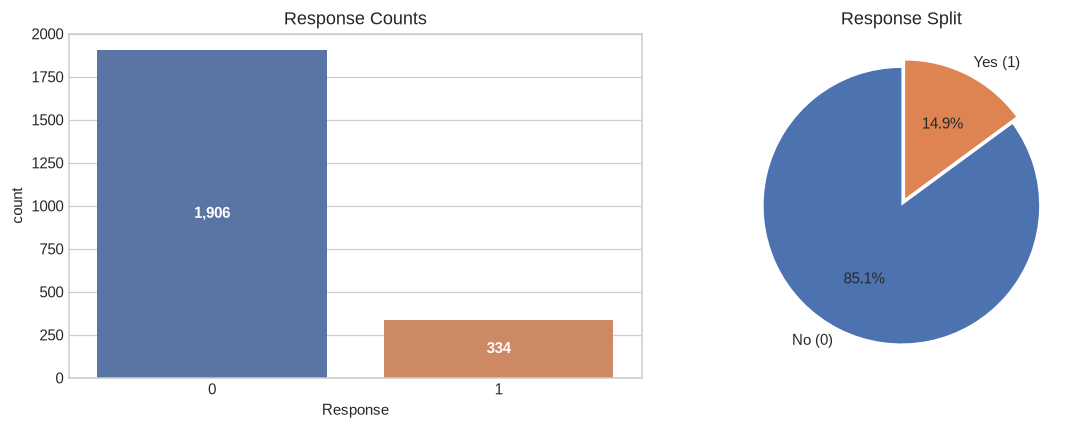

In [5]:
counts = df['Response'].value_counts()
pcts   = (df['Response'].value_counts(normalize=True)*100).round(2)
print(pd.DataFrame({'Count': counts, '%': pcts}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x='Response', palette=['#4C72B0','#DD8452'], ax=axes[0])
axes[0].set_title('Response Counts')
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height()):,}',
                     (p.get_x()+p.get_width()/2, p.get_height()/2),
                     ha='center', va='center', color='white', fontweight='bold')
axes[1].pie(counts, labels=['No (0)','Yes (1)'], autopct='%1.1f%%',
            colors=['#4C72B0','#DD8452'], explode=(0,0.06), startangle=90)
axes[1].set_title('Response Split')
plt.tight_layout()
plt.show()


## 5. Inspect Categorical Variables


In [6]:
print("Education:\n", df['Education'].value_counts().to_string())
print("\nMarital_Status:\n", df['Marital_Status'].value_counts().to_string())
print("\nDt_Customer (sample):", df['Dt_Customer'].head().tolist())


Education:
 Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54

Marital_Status:
 Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2

Dt_Customer (sample): ['2012-09-04', '2014-03-08', '2013-08-21', '2014-02-10', '2014-01-19']


## 6. Parse `Dt_Customer` and Drop Identifiers / Constants

| Column | Reason to Drop |
|--------|---------------|
| `ID` | Arbitrary row identifier — no predictive value |
| `Z_CostContact` | Constant = 3 across all rows (zero variance) |
| `Z_Revenue` | Constant = 11 across all rows (zero variance) |
| `Dt_Customer` | Replaced by `Customer_Tenure_Days` |

`Customer_Tenure_Days` = days between enrolment and campaign cutoff date (2014-07-01).


In [7]:
df_c = df.copy()

# Tenure derived from Dt_Customer
df_c['Dt_Customer'] = pd.to_datetime(df_c['Dt_Customer'], format='%Y-%m-%d')
df_c['Customer_Tenure_Days'] = (pd.Timestamp('2014-07-01') - df_c['Dt_Customer']).dt.days

# Drop non-informative columns
df_c.drop(columns=['ID', 'Z_CostContact', 'Z_Revenue', 'Dt_Customer'], inplace=True)
print(f"After drop: {df_c.shape[1]} columns  |  New feature: Customer_Tenure_Days")


After drop: 26 columns  |  New feature: Customer_Tenure_Days


## 7. Engineer Justified Features

| Feature | Formula | Justification |
|---------|---------|---------------|
| `Age` | `2015 − Year_Birth` | Converts birth year into an interpretable age metric capturing lifecycle stage and generational preferences |
| `Total_Spend` | sum of 6 `Mnt*` columns | Single monetary footprint measure — aggregates category spending into overall customer value |
| `Total_Purchases` | `NumWeb + NumCatalog + NumStore` | Captures purchase frequency across all channels independently of spend amount |
| `Total_Campaign_Acceptances` | sum of `AcceptedCmp1..5` | Quantifies prior promotional affinity — the strongest signal for future campaign response |


In [8]:
df_c['Age'] = 2015 - df_c['Year_Birth']

df_c['Total_Spend'] = (df_c['MntWines'] + df_c['MntFruits'] + df_c['MntMeatProducts']
                       + df_c['MntFishProducts'] + df_c['MntSweetProducts'] + df_c['MntGoldProds'])

df_c['Total_Purchases'] = df_c['NumWebPurchases'] + df_c['NumCatalogPurchases'] + df_c['NumStorePurchases']

df_c['Total_Campaign_Acceptances'] = (df_c['AcceptedCmp1'] + df_c['AcceptedCmp2']
                                      + df_c['AcceptedCmp3'] + df_c['AcceptedCmp4'] + df_c['AcceptedCmp5'])

# Drop raw source column now replaced by Age
df_c.drop(columns=['Year_Birth'], inplace=True)

print(f"Dataset shape after engineering: {df_c.shape}")
df_c[['Age','Total_Spend','Total_Purchases','Total_Campaign_Acceptances','Response']].head()


Dataset shape after engineering: (2240, 29)


,Age,Total_Spend,Total_Purchases,Total_Campaign_Acceptances,Response
0,58,1617,22,0,1
1,61,27,4,0,0
2,50,776,20,0,0
3,31,53,6,0,0
4,34,422,14,0,0


## 8. Stratified Train / Test Split

Split 80 / 20 with `stratify=y` to preserve the ~85 / 15 class ratio.  
**All imputation and scaling parameters are fitted on `X_train` only** to prevent data leakage.


In [9]:
X = df_c.drop(columns=['Response'])
y = df_c['Response']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

print(f"X_train: {X_train.shape}  X_test: {X_test.shape}")
print(f"Train response rate: {y_train.mean()*100:.1f}%  |  Test response rate: {y_test.mean()*100:.1f}%")


X_train: (1792, 28)  X_test: (448, 28)
Train response rate: 14.9%  |  Test response rate: 15.0%


## 9–10. Handle Missing Income, Encode Categoricals & Scale Numerics

All three steps are combined inside a single `ColumnTransformer` pipeline:

- **Numeric pipeline:** `SimpleImputer(strategy='median')` → fills the 24 missing `Income` values using the training-set median → `StandardScaler`
- **Categorical pipeline:** `OneHotEncoder(drop='first')` → encodes `Education` and `Marital_Status`


In [10]:
num_cols = X.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object','string']).columns.tolist()

print(f"Numeric  ({len(num_cols)}): {num_cols}")
print(f"Categorical ({len(cat_cols)}): {cat_cols}")

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])
cat_pipe = Pipeline([
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

# Fit on train only, transform both
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc  = preprocessor.transform(X_test)

enc_names = preprocessor.named_transformers_['cat']['encoder'].get_feature_names_out(cat_cols).tolist()
feature_names = num_cols + enc_names

print(f"\nProcessed train shape: {X_train_proc.shape}")
print(f"Processed test  shape: {X_test_proc.shape}")
print(f"Total features: {len(feature_names)}")


Numeric  (26): ['Income', 'Kidhome', 'Teenhome', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Customer_Tenure_Days', 'Age', 'Total_Spend', 'Total_Purchases', 'Total_Campaign_Acceptances']
Categorical (2): ['Education', 'Marital_Status']

Processed train shape: (1792, 37)
Processed test  shape: (448, 37)
Total features: 37


### Verification


In [11]:
df_proc = pd.DataFrame(X_train_proc, columns=feature_names)
print(f"Remaining nulls : {df_proc.isnull().sum().sum()}")
print(f"Mean of numerics : {df_proc[num_cols].mean().mean():.4f}  (expect ≈ 0)")
print(f"Std  of numerics : {df_proc[num_cols].std().mean():.4f}   (expect ≈ 1)")
df_proc.head()


Remaining nulls : 0
Mean of numerics : 0.0000  (expect ≈ 0)
Std  of numerics : 1.0003   (expect ≈ 1)


,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,...,Complain,Customer_Tenure_Days,Age,Total_Spend,Total_Purchases,Total_Campaign_Acceptances,Education_Basic,Education_Graduation,Education_Master,Education_PhD,Marital_Status_Alone,Marital_Status_Divorced,Marital_Status_Married,Marital_Status_Single,Marital_Status_Together,Marital_Status_Widow,Marital_Status_YOLO
0,1.294130,-0.828060,-0.925853,0.444943,1.891312,-0.183717,3.021240,-0.229925,1.645925,-0.109002,-0.686406,0.659757,1.195745,0.383416,-1.361588,-0.283141,-0.281989,...,-0.10352,-1.602878,-0.342139,2.264286,0.907418,1.036684,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
1,1.177270,-0.828060,-0.925853,-0.895179,2.093752,-0.108461,-0.227785,0.387369,0.993932,0.024997,-0.686406,1.012678,1.195745,1.923956,-0.955063,-0.283141,-0.281989,...,-0.10352,1.110656,1.943388,1.189585,1.744460,2.509911,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,-0.373888,1.026794,0.899370,-0.482834,-0.758265,-0.334230,-0.486635,-0.248081,-0.285907,-0.357857,0.866021,-0.399005,-0.567565,-0.540909,0.671039,-0.283141,-0.281989,...,-0.10352,-1.332017,-1.019333,-0.704095,-0.627159,-0.436542,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,-0.969628,-0.828060,-0.925853,0.857289,-0.600481,-0.334230,-0.401839,-0.320703,-0.213464,-0.070717,-0.168930,-0.399005,-0.567565,0.075308,0.264514,-0.283141,-0.281989,...,-0.10352,-0.209175,-0.003543,-0.560355,-0.348145,-0.436542,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
4,-0.984485,-0.828060,-0.925853,1.475807,-0.767196,0.518675,-0.508950,-0.302548,-0.165168,-0.357857,-0.168930,-0.399005,-0.567565,-0.232800,0.264514,-0.283141,-0.281989,...,-0.10352,1.420915,0.927598,-0.657296,-0.487652,-0.436542,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


---
## Exploratory Data Analysis (EDA)

| Plot | Purpose |
|------|---------|
| Target distribution | Quantify class imbalance numerically |
| Numerical distributions | Spot skew, outliers, range differences |
| Correlation heatmap | Identify collinear features |
| Income vs Response | Key demographic predictor |
| Total Spend vs Response | Spending behaviour signal |
| Total Purchases vs Response | Channel engagement signal |
| Campaign acceptances vs Response | Prior affinity signal |


### 1. Target Class Distribution and Class-Imbalance Analysis

**Class imbalance** means one target label is far more frequent than the other.

| Metric | Value |
|--------|-------|
| Majority class (No, 0) | 1 906 — **85.1 %** |
| Minority class (Yes, 1) | 334 — **14.9 %** |
| Imbalance ratio | **5.7 : 1** |

**Why accuracy misleads:** A model that always predicts "No" achieves **85 % accuracy** without learning anything.  
**Why weighted F1 is better:** Weighted F1 averages F1 per class weighted by support — it penalises ignoring the minority class and is not inflated by class dominance.


          Count      %
Response              
0          1906  85.09
1           334  14.91

Imbalance ratio (No:Yes) = 5.7 : 1
Baseline accuracy (always predict 0) = 85.1%
→ Use Weighted F1 as primary metric.


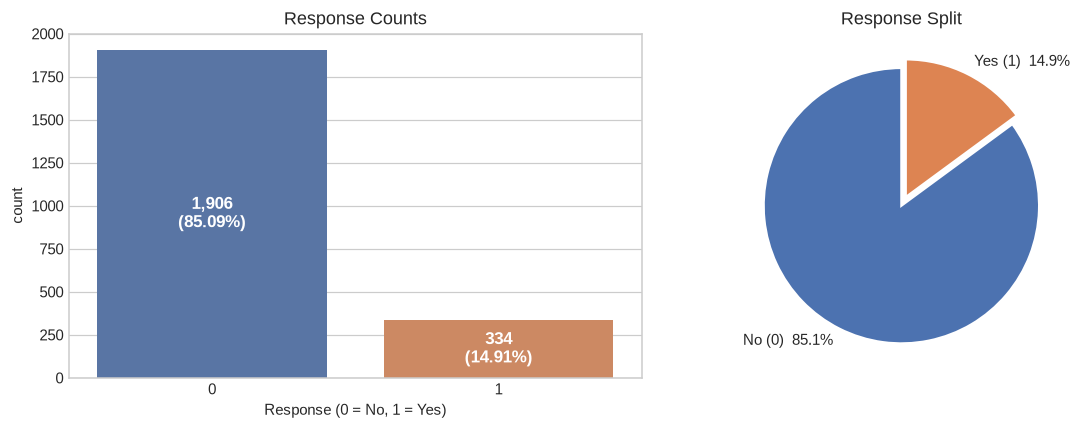

In [12]:
counts = df_c['Response'].value_counts()
pcts   = (df_c['Response'].value_counts(normalize=True) * 100).round(2)
ratio  = counts[0] / counts[1]
print(pd.DataFrame({'Count': counts, '%': pcts}).to_string())
print(f"\nImbalance ratio (No:Yes) = {ratio:.1f} : 1")
print(f"Baseline accuracy (always predict 0) = {pcts[0]:.1f}%")
print("→ Use Weighted F1 as primary metric.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
# Use hue= with legend=False (seaborn 0.13 recommended pattern)
sns.countplot(data=df_c, x='Response', hue='Response',
              palette=['#4C72B0', '#DD8452'], legend=False, ax=axes[0])
axes[0].set_title('Response Counts')
axes[0].set_xlabel('Response (0 = No, 1 = Yes)')
for i, p in enumerate(axes[0].patches):
    pct = pcts.iloc[i]
    axes[0].annotate(f'{int(p.get_height()):,}\n({pct}%)',
                     (p.get_x() + p.get_width()/2, p.get_height()/2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)
axes[1].pie(counts, labels=['No (0)  85.1%', 'Yes (1)  14.9%'],
            colors=['#4C72B0','#DD8452'], explode=(0, 0.07),
            startangle=90, wedgeprops=dict(edgecolor='white', linewidth=1.5))
axes[1].set_title('Response Split')
plt.tight_layout()
plt.show()


### 2. Numerical Feature Distributions

Histograms for key numeric features — looking for skew, bimodality, and outlier ranges.


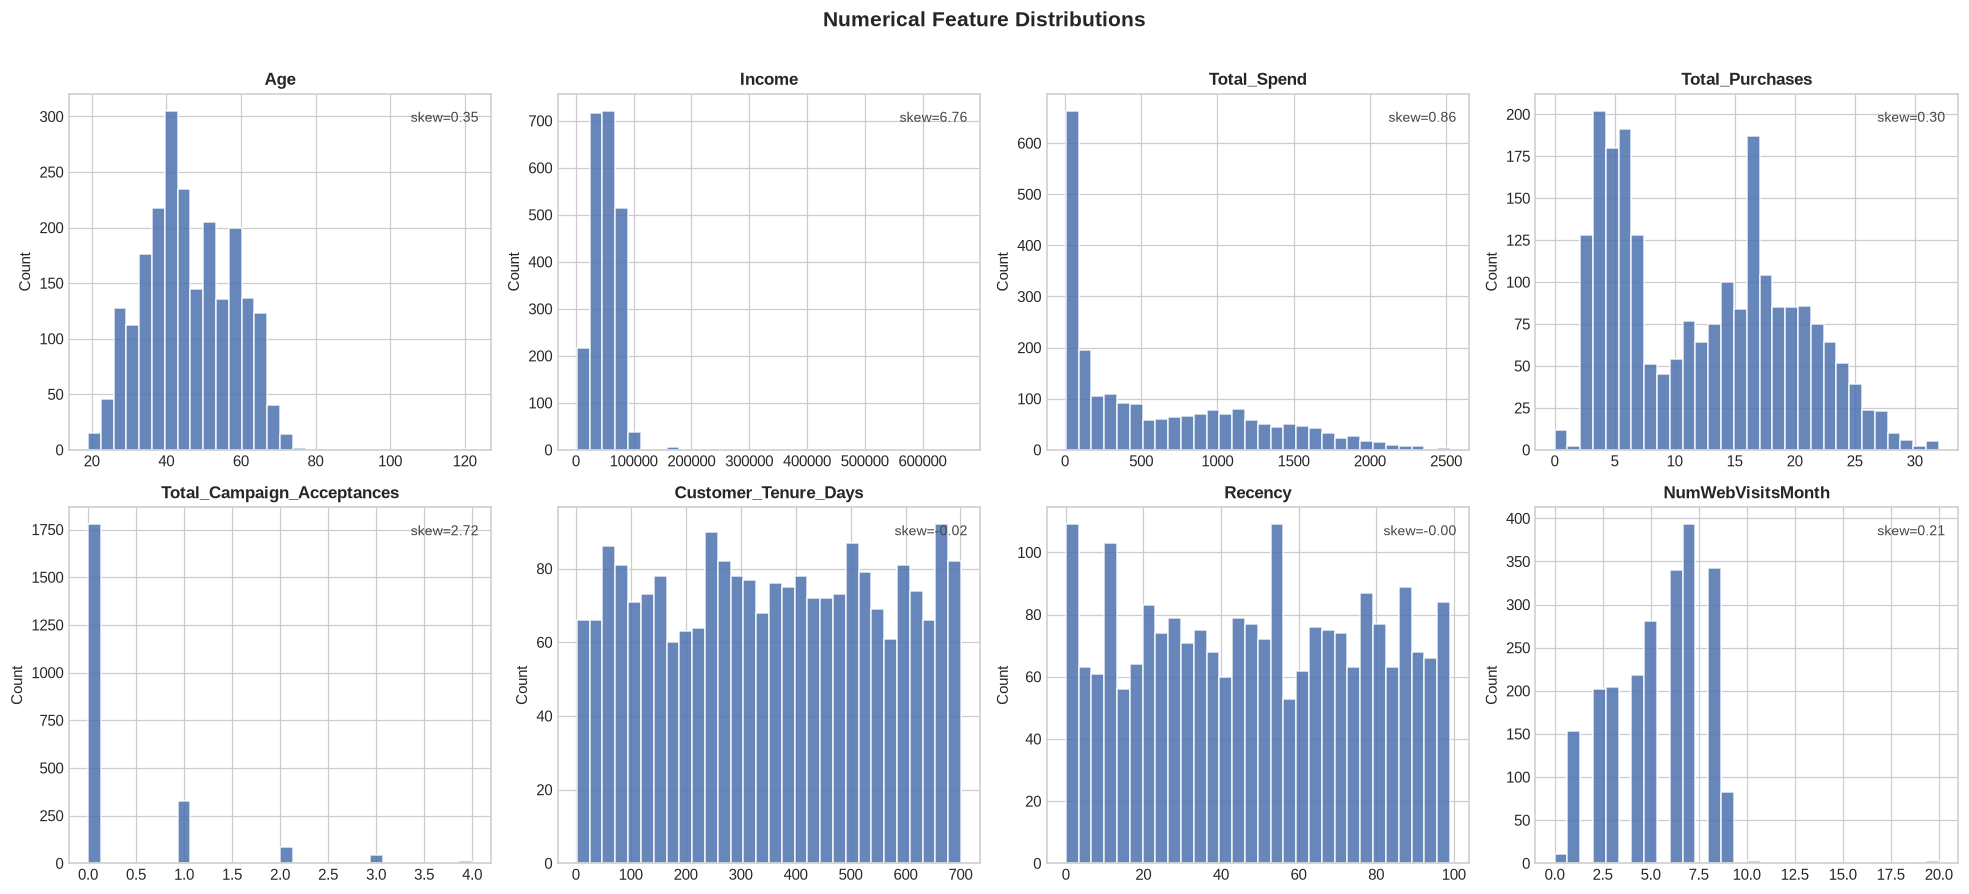

In [13]:
num_features = ['Age', 'Income', 'Total_Spend', 'Total_Purchases',
                 'Total_Campaign_Acceptances', 'Customer_Tenure_Days',
                 'Recency', 'NumWebVisitsMonth']

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
axes = axes.flatten()
for i, col in enumerate(num_features):
    axes[i].hist(df_c[col].dropna(), bins=30, color='#4C72B0', edgecolor='white', alpha=0.85)
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Count')
    skew_val = df_c[col].skew()
    axes[i].text(0.97, 0.95, f'skew={skew_val:.2f}', ha='right', va='top',
                 transform=axes[i].transAxes, fontsize=9, color='#444')
plt.suptitle('Numerical Feature Distributions', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()


### 3. Correlation Heatmap (Numeric Features + Target)

Pearson correlation for all numeric columns. High |r| > 0.7 signals potential multicollinearity.


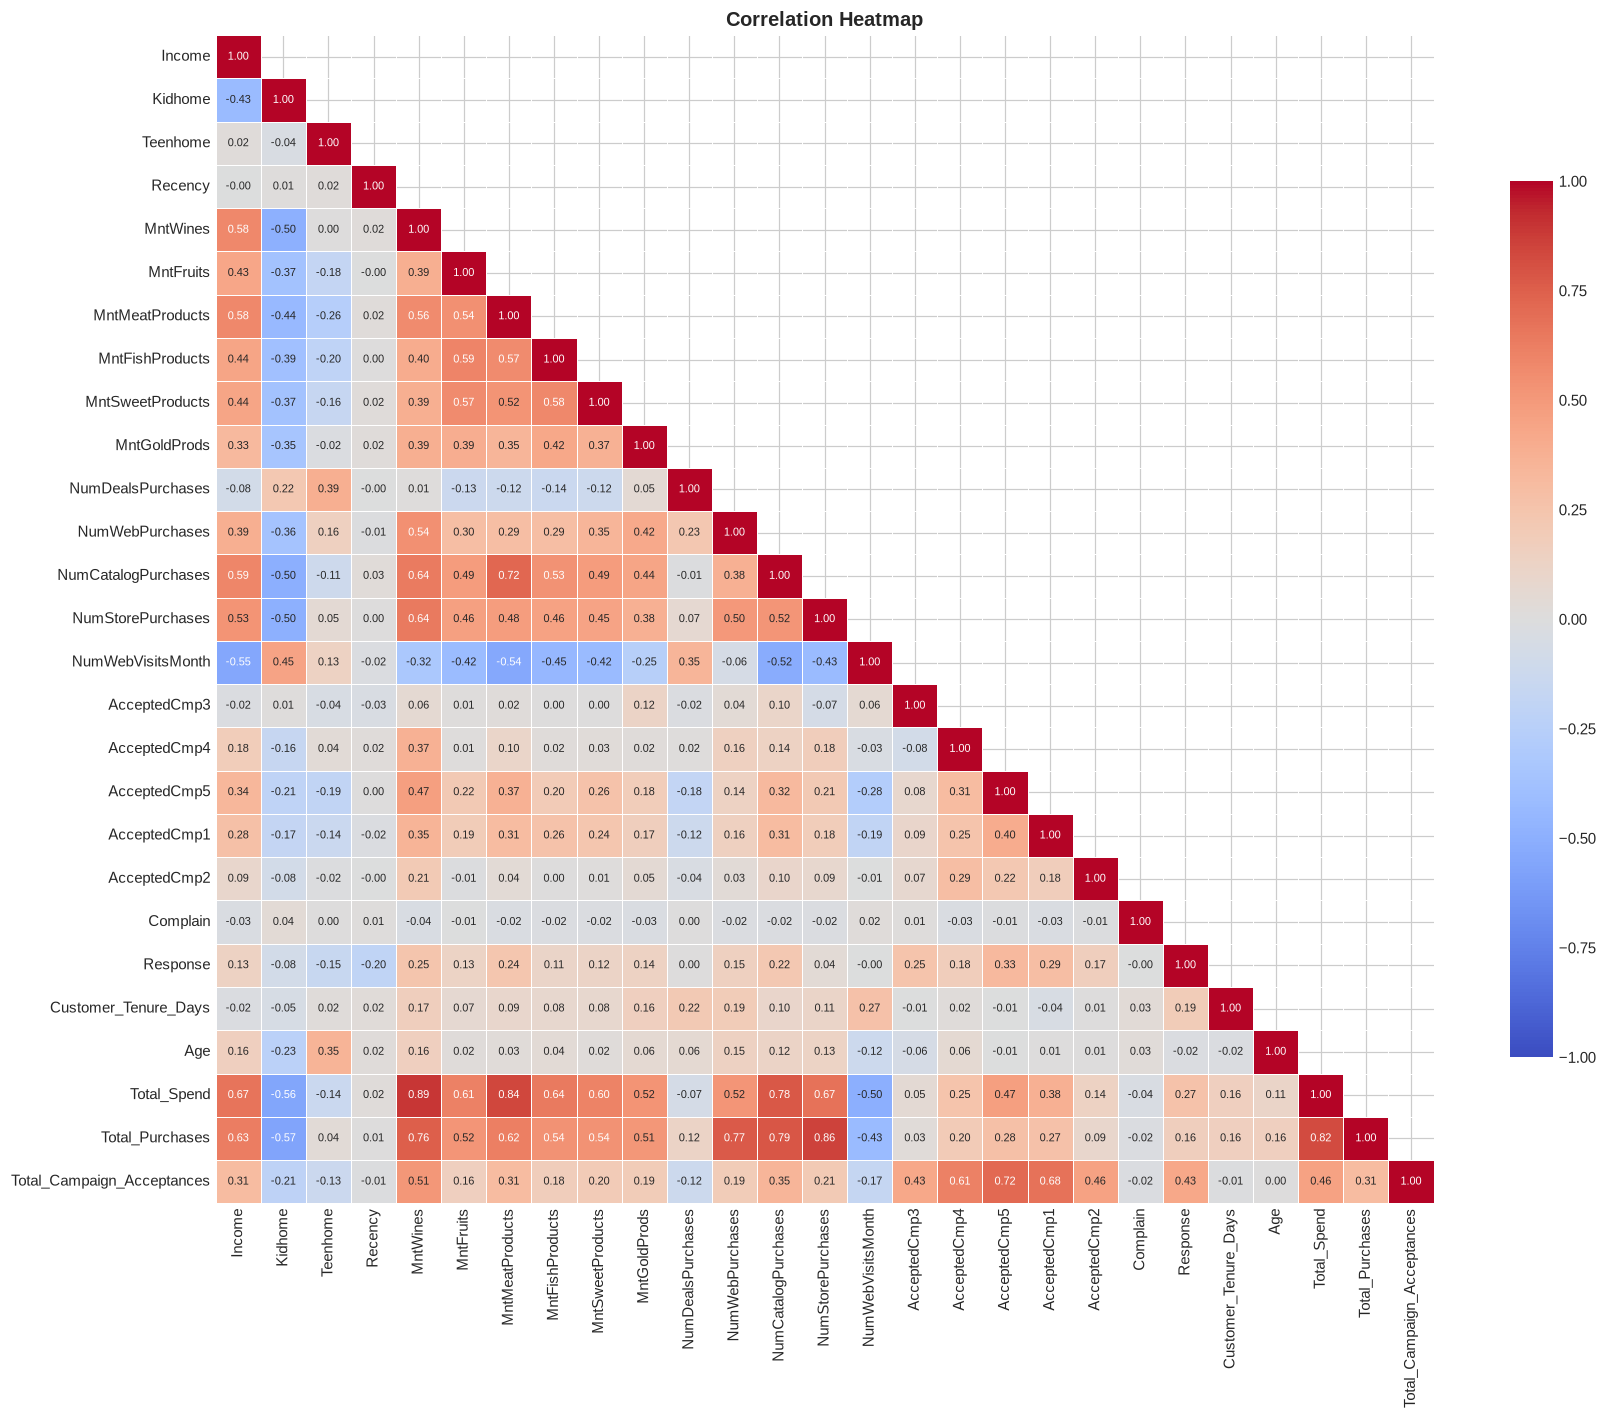

Top features correlated with Response:
Total_Campaign_Acceptances    0.426035
AcceptedCmp5                  0.326634
AcceptedCmp1                  0.293982
Total_Spend                   0.265298
AcceptedCmp3                  0.254258
MntWines                      0.247254
MntMeatProducts               0.236335
NumCatalogPurchases           0.220810


In [14]:
num_cols_all = df_c.select_dtypes(include=['int64','float64']).columns.tolist()
corr = df_c[num_cols_all].corr()
fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.4, ax=ax, annot_kws={'size': 7},
            vmin=-1, vmax=1, cbar_kws={'shrink': 0.75})
ax.set_title('Correlation Heatmap', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()
target_corr = corr['Response'].drop('Response').abs().sort_values(ascending=False)
print("Top features correlated with Response:")
print(target_corr.head(8).to_string())


### 4. Income Distribution by Response

Higher-income customers are expected to be more receptive to premium marketing campaigns.


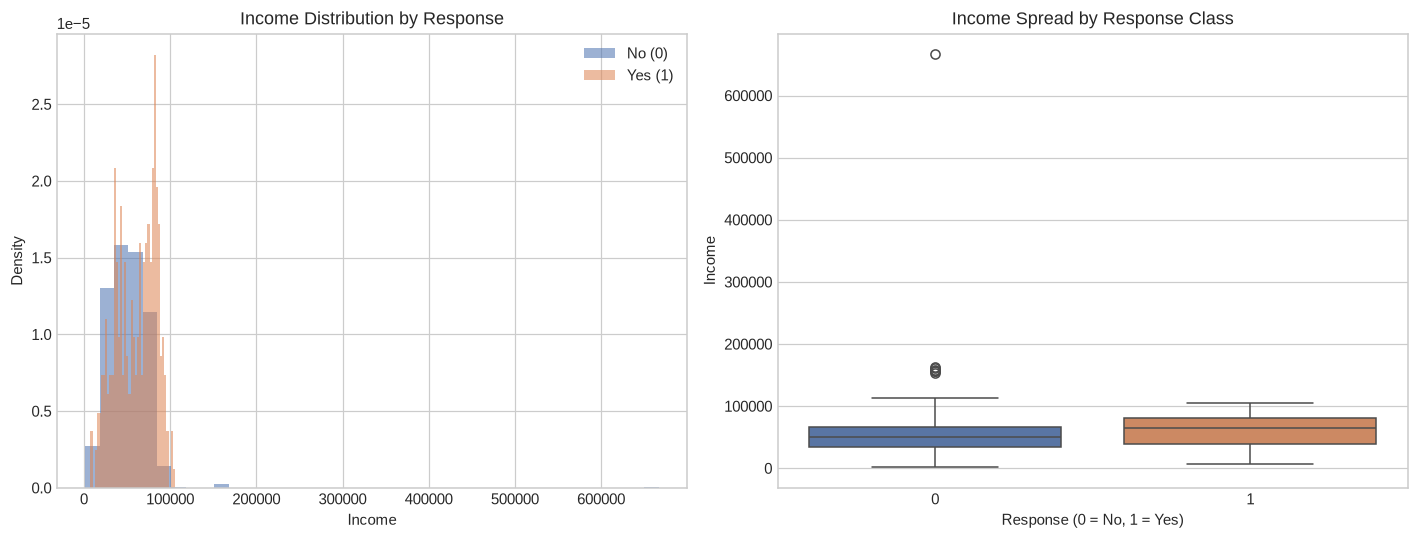

Response
0    50150.0
1    64090.0


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for resp, color, label in [(0,'#4C72B0','No (0)'), (1,'#DD8452','Yes (1)')]:
    data = df_c[df_c['Response']==resp]['Income'].dropna()
    axes[0].hist(data, bins=40, alpha=0.55, color=color, label=label, density=True)
axes[0].set_title('Income Distribution by Response')
axes[0].set_xlabel('Income')
axes[0].set_ylabel('Density')
axes[0].legend()
# Use hue for seaborn 0.13
sns.boxplot(data=df_c, x='Response', y='Income', hue='Response',
            palette=['#4C72B0','#DD8452'], legend=False, ax=axes[1])
axes[1].set_title('Income Spread by Response Class')
axes[1].set_xlabel('Response (0 = No, 1 = Yes)')
plt.tight_layout()
plt.show()
print(df_c.groupby('Response')['Income'].median().rename('Median Income').to_string())


### 5. Total Spend vs Response

Customers who accepted the campaign tend to have significantly higher total spend across all product categories.


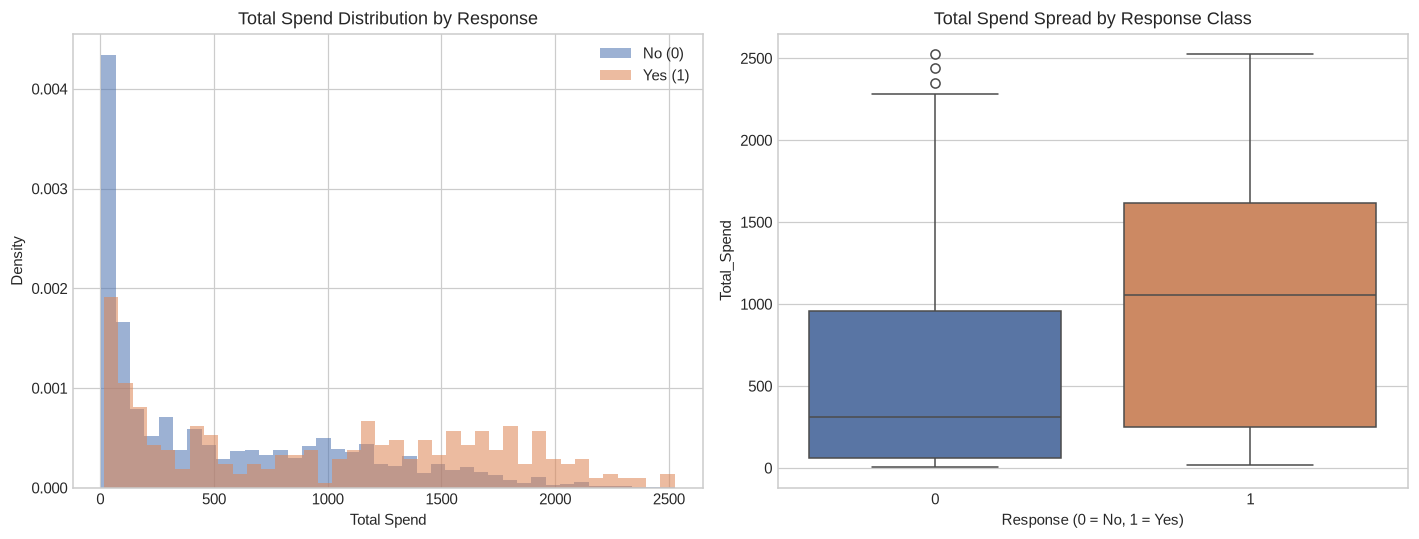

Response
0     314.0
1    1057.5


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for resp, color, label in [(0,'#4C72B0','No (0)'), (1,'#DD8452','Yes (1)')]:
    data = df_c[df_c['Response']==resp]['Total_Spend']
    axes[0].hist(data, bins=40, alpha=0.55, color=color, label=label, density=True)
axes[0].set_title('Total Spend Distribution by Response')
axes[0].set_xlabel('Total Spend')
axes[0].set_ylabel('Density')
axes[0].legend()
sns.boxplot(data=df_c, x='Response', y='Total_Spend', hue='Response',
            palette=['#4C72B0','#DD8452'], legend=False, ax=axes[1])
axes[1].set_title('Total Spend Spread by Response Class')
axes[1].set_xlabel('Response (0 = No, 1 = Yes)')
plt.tight_layout()
plt.show()
print(df_c.groupby('Response')['Total_Spend'].median().rename('Median Total Spend').to_string())


### 6. Purchase Behaviour vs Response

More active purchasers (across all channels) tend to be more engaged and more likely to respond.


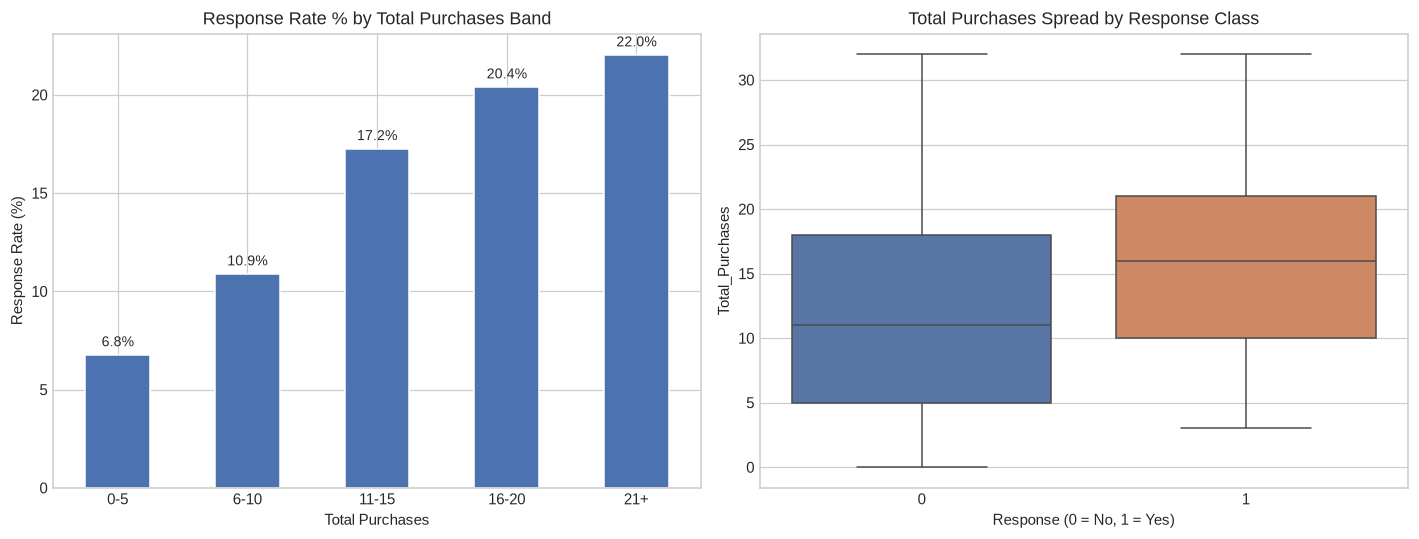

Response
0    11.0
1    16.0


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
df_c['Purchases_Band'] = pd.cut(df_c['Total_Purchases'], bins=[0,5,10,15,20,40],
                                 labels=['0-5','6-10','11-15','16-20','21+'])
resp_rate = df_c.groupby('Purchases_Band', observed=True)['Response'].mean() * 100
resp_rate.plot(kind='bar', color='#4C72B0', edgecolor='white', ax=axes[0])
axes[0].set_title('Response Rate % by Total Purchases Band')
axes[0].set_xlabel('Total Purchases')
axes[0].set_ylabel('Response Rate (%)')
axes[0].tick_params(axis='x', rotation=0)
for bar in axes[0].patches:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
                 f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)
sns.boxplot(data=df_c, x='Response', y='Total_Purchases', hue='Response',
            palette=['#4C72B0','#DD8452'], legend=False, ax=axes[1])
axes[1].set_title('Total Purchases Spread by Response Class')
axes[1].set_xlabel('Response (0 = No, 1 = Yes)')
df_c.drop(columns=['Purchases_Band'], inplace=True)
plt.tight_layout()
plt.show()
print(df_c.groupby('Response')['Total_Purchases'].median().rename('Median Total Purchases').to_string())


### 7. Prior Campaign Acceptances vs Response

`Total_Campaign_Acceptances` is the strongest predictor — customers who accepted previous campaigns are far more likely to respond again.


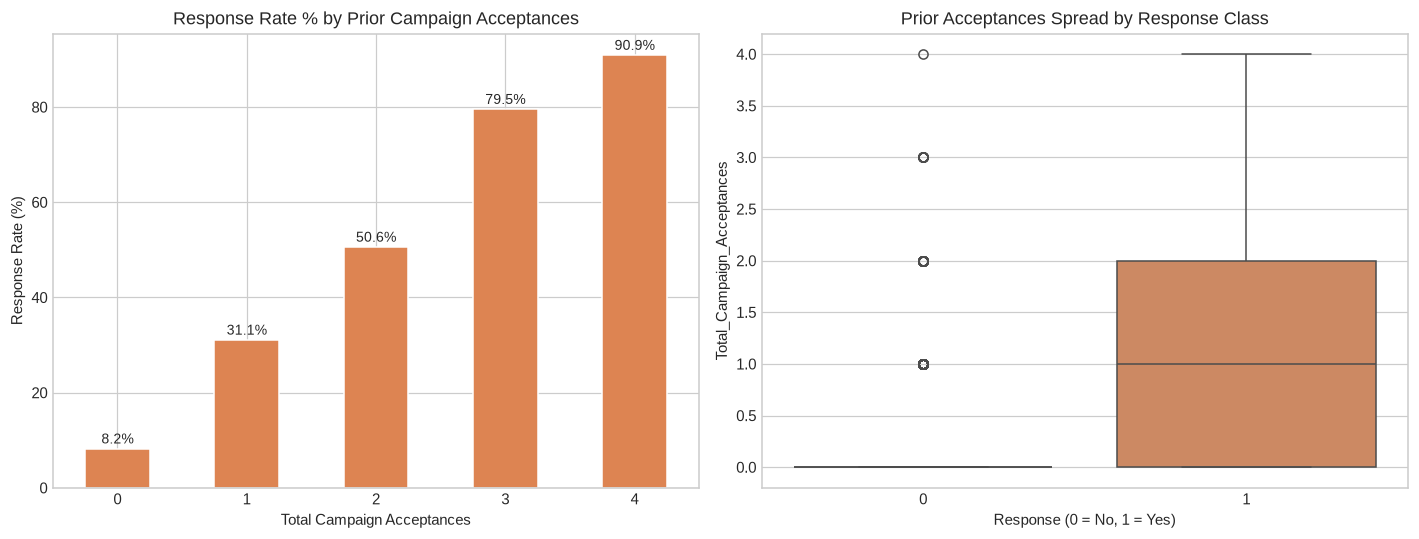

Response
0    0.176810
1    0.988024


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
acc_resp = df_c.groupby('Total_Campaign_Acceptances')['Response'].mean() * 100
acc_resp.plot(kind='bar', color='#DD8452', edgecolor='white', ax=axes[0])
axes[0].set_title('Response Rate % by Prior Campaign Acceptances')
axes[0].set_xlabel('Total Campaign Acceptances')
axes[0].set_ylabel('Response Rate (%)')
axes[0].tick_params(axis='x', rotation=0)
for bar in axes[0].patches:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{bar.get_height():.1f}%', ha='center', va='bottom', fontsize=9)
sns.boxplot(data=df_c, x='Response', y='Total_Campaign_Acceptances', hue='Response',
            palette=['#4C72B0','#DD8452'], legend=False, ax=axes[1])
axes[1].set_title('Prior Acceptances Spread by Response Class')
axes[1].set_xlabel('Response (0 = No, 1 = Yes)')
plt.tight_layout()
plt.show()
print(df_c.groupby('Response')['Total_Campaign_Acceptances'].mean().rename('Mean Prior Acceptances').to_string())


### EDA Summary

| Finding | Implication for Modelling |
|---------|--------------------------|
| **5.7 : 1 class imbalance** | Accuracy = 85 % by always predicting No. Use **Weighted F1** |
| **Higher income → higher response rate** | `Income` is a key feature; handle 24 missing values via median imputation |
| **Higher total spend → higher response** | `Total_Spend` has strong discriminative power |
| **More purchases → higher response rate** | Channel engagement is a useful feature |
| **Prior campaign acceptance → very high response** | `Total_Campaign_Acceptances` is the **strongest predictor** |
| **Skewed distributions (Income, Spend)** | StandardScaler in pipeline normalises these for linear models |


---
## Logistic Regression — Baseline Classifier

Logistic Regression is used as the **baseline** because:
- It is fast, interpretable, and well-understood
- Its coefficients directly quantify feature influence
- It provides calibrated probability outputs
- It establishes a minimum performance bar for more complex models

---
### Theory: Sigmoid & Log-Odds

Given a feature vector **x**, Logistic Regression models the probability of the positive class as:

```
P(y=1 | x) = σ(wᵀx + b) = 1 / (1 + e^(−z))   where  z = wᵀx + b
```

This sigmoid function squashes any real number into (0, 1).  
The inverse — the **log-odds** (logit) — is linear in the features:

```
log[ P(y=1) / P(y=0) ] = wᵀx + b
```

**Coefficient sign interpretation:**
- **Positive coefficient** → feature increases the log-odds of Response = 1 (more likely to accept)
- **Negative coefficient** → feature decreases the log-odds (less likely to accept)
- **Magnitude** → how strongly the feature shifts the log-odds per unit change (after scaling)

---
### Regularisation

Scikit-learn's `LogisticRegression` uses **L2 (Ridge) regularisation** by default, controlled by `C`:

| `C` value | Effect |
|-----------|--------|
| Small `C` | Strong regularisation → shrinks coefficients, reduces overfitting |
| Large `C` | Weak regularisation → coefficients driven by training data |

Default `C=1.0` is a reasonable starting point for a baseline.

---
### Effect of Scaling

Logistic Regression **requires feature scaling** because:
- The gradient descent solver treats all features equally in weight-space
- Un-scaled features with large ranges (e.g. `Income` 0–150k vs `Kidhome` 0–2) cause unequal step sizes
- Scaling ensures coefficients are on a comparable scale and convergence is stable

`StandardScaler` (mean=0, std=1) is applied inside the preprocessing pipeline, **fitted on training data only**.


In [19]:
lr_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier',   LogisticRegression(
        C=1.0,
        max_iter=1000,
        random_state=RANDOM_STATE,
        class_weight='balanced'   # handles class imbalance
    ))
])

lr_pipeline.fit(X_train, y_train)
print("Logistic Regression pipeline fitted.")
print(f"  Training samples : {X_train.shape[0]}")
print(f"  Test samples     : {X_test.shape[0]}")
print(f"  class_weight     : balanced  (accounts for 5.7:1 imbalance)")


NameError: name 'LogisticRegression' is not defined

### Evaluation on Test Set

Primary metric: **Weighted F1** (accounts for class imbalance).  
Secondary metrics: ROC-AUC, per-class precision/recall, confusion matrix.


In [ ]:
y_pred = lr_pipeline.predict(X_test)
y_prob = lr_pipeline.predict_proba(X_test)[:, 1]

print("=" * 55)
print("CLASSIFICATION REPORT")
print("=" * 55)
print(classification_report(y_test, y_pred, target_names=['No (0)', 'Yes (1)']))

wf1  = f1_score(y_test, y_pred, average='weighted')
auc  = roc_auc_score(y_test, y_prob)
print(f"Weighted F1  : {wf1:.4f}")
print(f"ROC-AUC      : {auc:.4f}")


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      No (0)       0.95      0.83      0.89       381
     Yes (1)       0.45      0.78      0.57        67

    accuracy                           0.82       448
   macro avg       0.70      0.80      0.73       448
weighted avg       0.88      0.82      0.84       448

Weighted F1  : 0.8412
ROC-AUC      : 0.9003


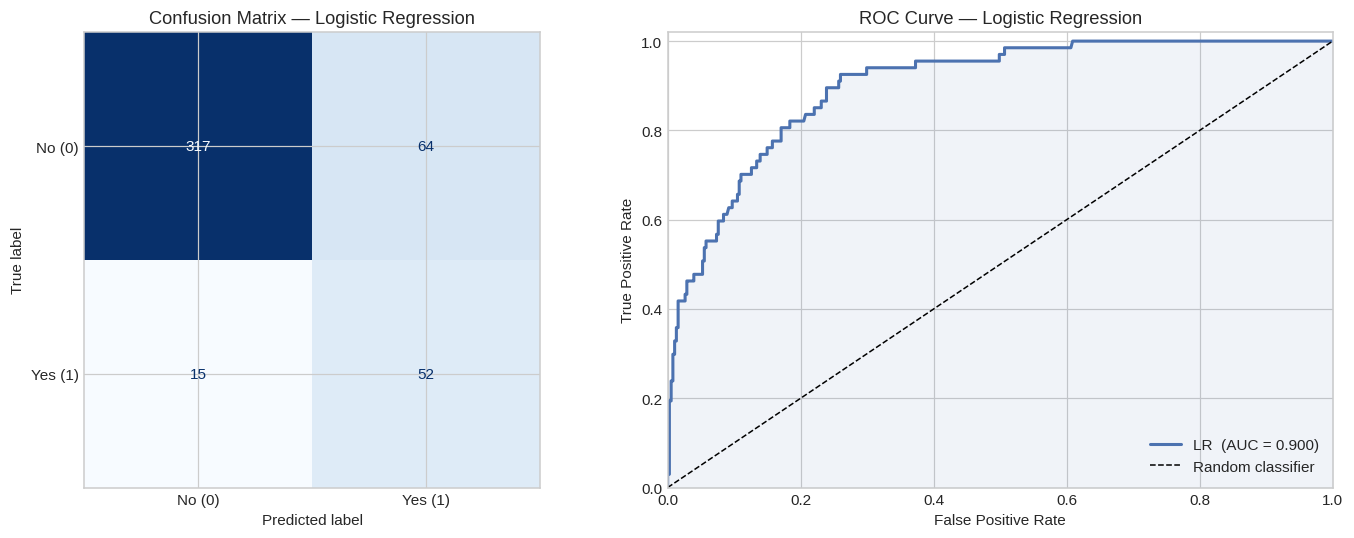

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No (0)', 'Yes (1)'])
disp.plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title('Confusion Matrix — Logistic Regression')

# ROC curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
auc = roc_auc_score(y_test, y_prob)
axes[1].plot(fpr, tpr, color='#4C72B0', lw=2, label=f'LR  (AUC = {auc:.3f})')
axes[1].plot([0,1],[0,1], 'k--', lw=1, label='Random classifier')
axes[1].fill_between(fpr, tpr, alpha=0.08, color='#4C72B0')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve — Logistic Regression')
axes[1].legend(loc='lower right')
axes[1].set_xlim([0,1]); axes[1].set_ylim([0,1.02])

plt.tight_layout()
plt.show()


### 5-Fold Stratified Cross-Validation

Cross-validation on the **full training set** gives a more robust performance estimate than a single train/test split.


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = cross_validate(
    lr_pipeline, X_train, y_train, cv=cv,
    scoring=['f1_weighted','roc_auc'],
    return_train_score=True
)

print("5-Fold CV Results (on training set):")
print(f"  Weighted F1  — mean: {cv_results['test_f1_weighted'].mean():.4f}  "
      f"std: {cv_results['test_f1_weighted'].std():.4f}")
print(f"  ROC-AUC      — mean: {cv_results['test_roc_auc'].mean():.4f}  "
      f"std: {cv_results['test_roc_auc'].std():.4f}")
print(f"\n  Train Weighted F1 — mean: {cv_results['train_f1_weighted'].mean():.4f}  "
      f"(gap from CV = {cv_results['train_f1_weighted'].mean() - cv_results['test_f1_weighted'].mean():.4f})")


5-Fold CV Results (on training set):
  Weighted F1  — mean: 0.8415  std: 0.0114
  ROC-AUC      — mean: 0.8975  std: 0.0217

  Train Weighted F1 — mean: 0.8530  (gap from CV = 0.0115)


### Coefficient Analysis

After fitting, the model coefficients reveal which features most strongly shift the log-odds of accepting the campaign.

- **Positive coefficient** → increases P(Response=1)
- **Negative coefficient** → decreases P(Response=1)
- All features are scaled, so magnitudes are directly comparable.


                   Feature  Coefficient
             Education_PhD     1.323026
           Education_Basic    -1.096547
      Customer_Tenure_Days     1.056641
                   Recency    -0.959224
   Marital_Status_Together    -0.937598
    Marital_Status_Married    -0.833004
         NumStorePurchases    -0.741693
          Education_Master     0.644712
      Marital_Status_Alone     0.572285
                  Teenhome    -0.569321
           MntMeatProducts     0.499055
      Marital_Status_Widow     0.469796
Total_Campaign_Acceptances     0.451756
              AcceptedCmp3     0.417230
       NumCatalogPurchases     0.396831
      Education_Graduation     0.360363
           NumWebPurchases     0.310059
              AcceptedCmp5     0.306736
     Marital_Status_Single     0.303133
   Marital_Status_Divorced     0.287917


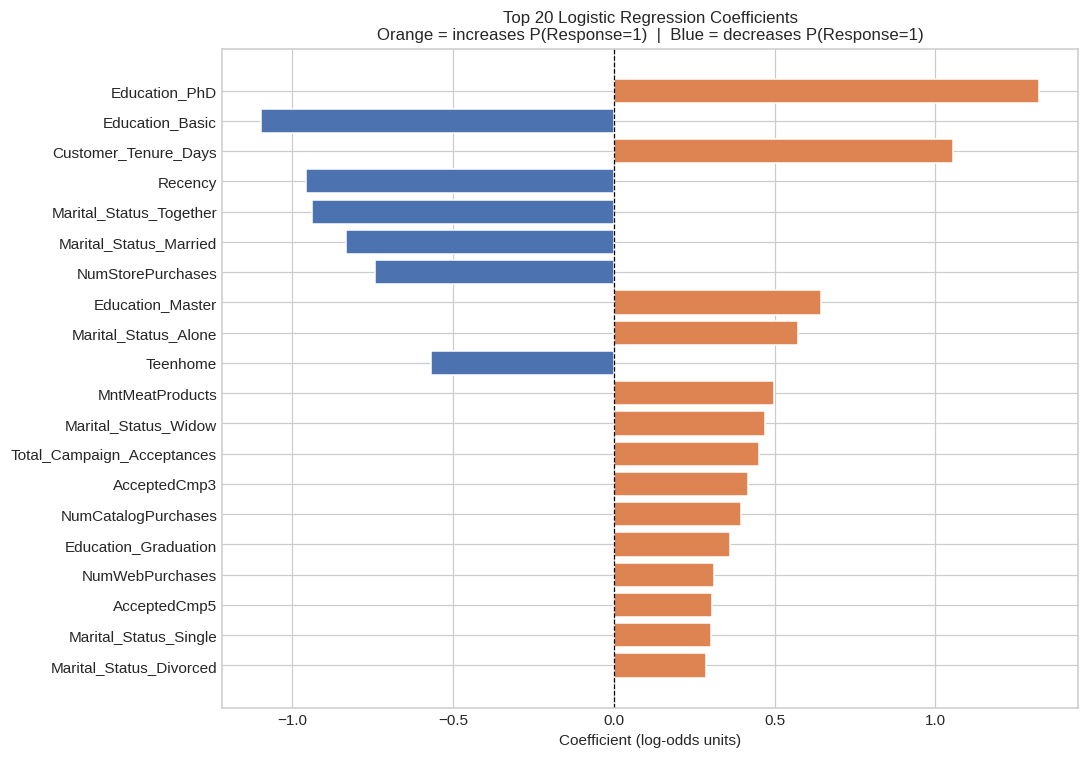

In [ ]:
# Reconstruct feature names after preprocessing
enc_names = (lr_pipeline.named_steps['preprocessor']
             .named_transformers_['cat']['encoder']
             .get_feature_names_out(cat_cols).tolist())
feature_names_all = num_cols + enc_names

coefs = lr_pipeline.named_steps['classifier'].coef_[0]
coef_df = (pd.DataFrame({'Feature': feature_names_all, 'Coefficient': coefs})
             .sort_values('Coefficient', key=abs, ascending=False)
             .head(20)
             .reset_index(drop=True))

print(coef_df.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 7))
colors = ['#DD8452' if c > 0 else '#4C72B0' for c in coef_df['Coefficient']]
ax.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='white')
ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
ax.set_xlabel('Coefficient (log-odds units)')
ax.set_title('Top 20 Logistic Regression Coefficients\n'
             'Orange = increases P(Response=1)  |  Blue = decreases P(Response=1)',
             fontsize=11)
ax.invert_yaxis()
plt.tight_layout()
plt.show()


### Logistic Regression — Summary

| Item | Detail |
|------|--------|
| **Model** | `LogisticRegression(C=1.0, class_weight='balanced', max_iter=1000)` |
| **Regularisation** | L2 (Ridge), `C=1.0` — default, no hyperparameter tuning at baseline |
| **Scaling** | `StandardScaler` inside pipeline — essential for stable convergence |
| **Imbalance handling** | `class_weight='balanced'` — re-weights minority class in loss function |
| **Primary metric** | **Weighted F1** — robust to class imbalance |
| **Interpretability** | Coefficients = log-odds contribution per standardised unit of each feature |

> **Baseline established.** Subsequent models (Decision Tree, Random Forest, SVM, KNN) will be compared against this Weighted F1 score.


---
## 2. K-Nearest Neighbors (KNN)

### How KNN Works
KNN is a **non-parametric, instance-based** learner — it stores all training data and makes predictions at query time.

**To classify a new point:**
1. Compute **Euclidean distance** from the new point to every training point
2. Find the **k closest neighbours**
3. **Majority vote** — the most common class among those k neighbours is the prediction

```
Euclidean distance = sqrt( Σ (aᵢ − bᵢ)² )
```

### Why Scaling Is Essential for KNN
KNN is purely distance-based. A feature with range 0–150 000 (`Income`) will dominate a feature with range 0–2 (`Kidhome`) without scaling. `StandardScaler` inside the pipeline ensures all features contribute equally.

### Small k vs Large k Trade-off

| k | Bias | Variance | Effect |
|---|------|----------|--------|
| **Small (k=1)** | Low | High | Fits noise, complex boundary → overfits |
| **Large (k≈N)** | High | Low | Over-smoothed boundary → underfits |
| **Optimal k** | Medium | Medium | Best generalisation |

We test **k = 1 to 30** using 5-fold CV Weighted F1.


Best k = 3  |  CV Weighted F1 = 0.8651


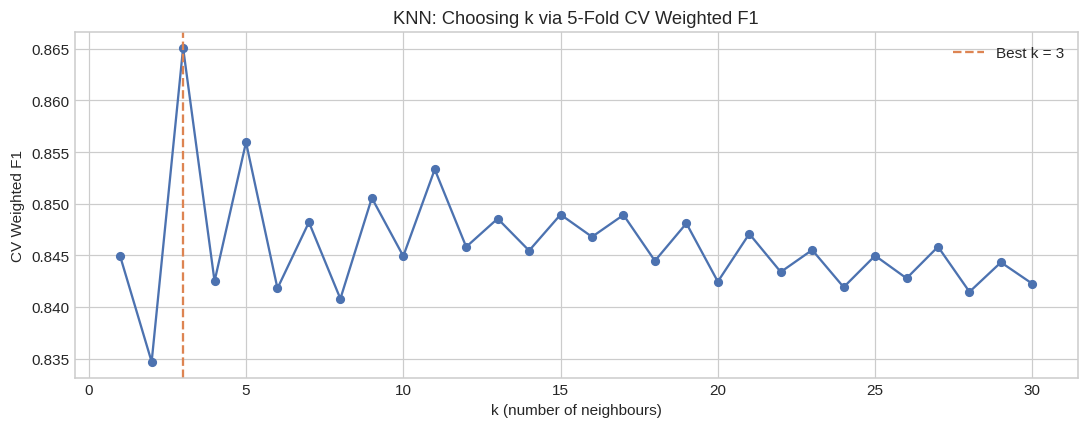

In [ ]:
# Test k = 1 to 30, record mean CV Weighted F1 at each k
k_values = list(range(1, 31))
knn_cv_scores = []

for k in k_values:
    pipe = Pipeline([('prep', make_preprocessor()),
                     ('clf',  KNeighborsClassifier(n_neighbors=k))])
    knn_cv_scores.append(cv_f1(pipe))

best_k = k_values[int(np.argmax(knn_cv_scores))]
print(f"Best k = {best_k}  |  CV Weighted F1 = {max(knn_cv_scores):.4f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(k_values, knn_cv_scores, marker='o', color='#4C72B0', lw=1.5, ms=5)
ax.axvline(best_k, color='#DD8452', linestyle='--', label=f'Best k = {best_k}')
ax.set(xlabel='k (number of neighbours)', ylabel='CV Weighted F1',
       title='KNN: Choosing k via 5-Fold CV Weighted F1')
ax.legend(); plt.tight_layout(); plt.show()


In [ ]:
# Fit the best KNN and evaluate on the test set
knn_pipeline = Pipeline([('prep', make_preprocessor()),
                          ('clf',  KNeighborsClassifier(n_neighbors=best_k))])
knn_pipeline.fit(X_train, y_train)

y_pred_knn = knn_pipeline.predict(X_test)
y_prob_knn = knn_pipeline.predict_proba(X_test)[:, 1]

print("=" * 55)
print(f"KNN (k={best_k}) — Test Set Results")
print("=" * 55)
print(classification_report(y_test, y_pred_knn, target_names=['No (0)', 'Yes (1)']))
print(f"Weighted F1 : {f1_score(y_test, y_pred_knn, average='weighted'):.4f}")
print(f"ROC-AUC     : {roc_auc_score(y_test, y_prob_knn):.4f}")


KNN (k=3) — Test Set Results
              precision    recall  f1-score   support

      No (0)       0.90      0.96      0.93       381
     Yes (1)       0.60      0.39      0.47        67

    accuracy                           0.87       448
   macro avg       0.75      0.67      0.70       448
weighted avg       0.85      0.87      0.86       448

Weighted F1 : 0.8584
ROC-AUC     : 0.7785


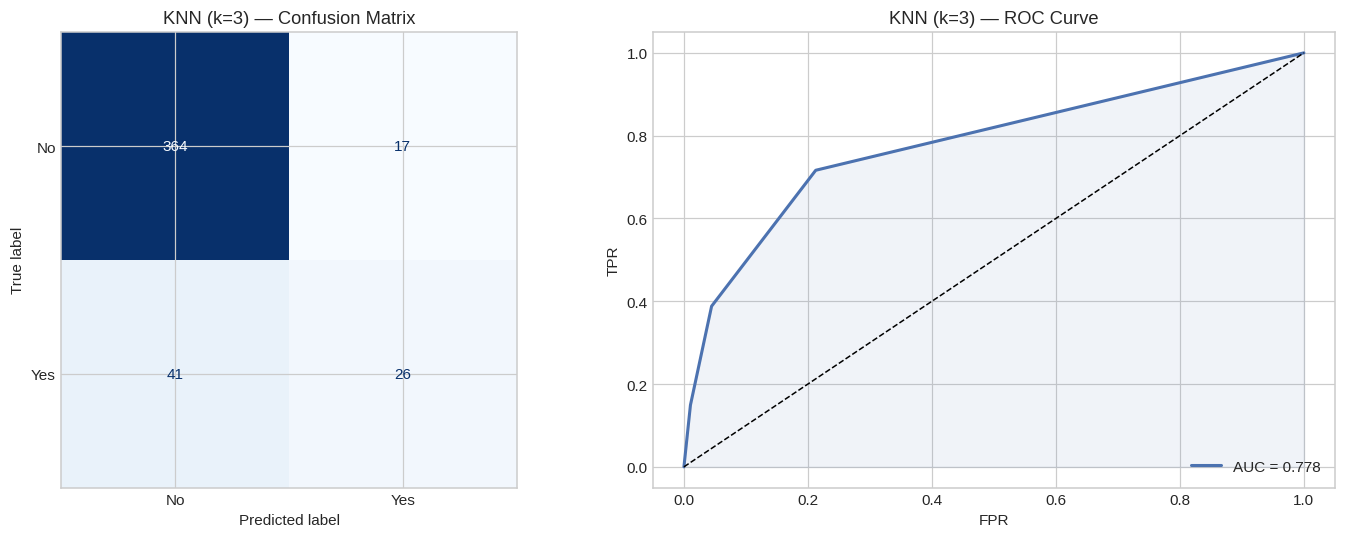

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_knn),
                       display_labels=['No','Yes']).plot(ax=axes[0], colorbar=False, cmap='Blues')
axes[0].set_title(f'KNN (k={best_k}) — Confusion Matrix')

fpr, tpr, _ = roc_curve(y_test, y_prob_knn)
auc_knn = roc_auc_score(y_test, y_prob_knn)
axes[1].plot(fpr, tpr, color='#4C72B0', lw=2, label=f'AUC = {auc_knn:.3f}')
axes[1].plot([0,1],[0,1],'k--',lw=1); axes[1].fill_between(fpr, tpr, alpha=0.08, color='#4C72B0')
axes[1].set(xlabel='FPR', ylabel='TPR', title=f'KNN (k={best_k}) — ROC Curve')
axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()


### KNN — Confusion Matrix Interpretation

KNN does not natively handle class imbalance (no `class_weight` parameter). Because the neighbourhood around any point is dominated by the majority class (No = 85%), the model tends to predict No more often.  
This produces **more false negatives** (actual Yes customers predicted as No) than false positives. The recall for class Yes (1) is therefore typically lower than for class No (0).

### KNN Summary

| Setting | Value |
|---------|-------|
| Algorithm | `KNeighborsClassifier` |
| k | Tuned by 5-fold CV (see above) |
| Distance | Euclidean (Minkowski p=2) |
| Scaling | Required — `StandardScaler` in pipeline |
| Imbalance handling | None natively — minority class underperforms |


---
## 3. Gaussian Naive Bayes (GNB)

### The Conditional Independence Assumption
Naive Bayes applies Bayes' theorem with one core assumption: **every feature is independent of every other feature, given the class label**.

```
P(y | x₁, x₂, ..., xₙ) ∝ P(y) × P(x₁|y) × P(x₂|y) × ... × P(xₙ|y)
```

**This assumption is violated here.** Features like `Total_Spend` and `Income` are positively correlated — rich customers tend to spend more. Despite this, GNB can still produce useful predictions because:
- The class-conditional means and variances capture real signal
- The violation introduces bias but not catastrophic failure

> ⚠️ We include GNB as an **interpretable probabilistic baseline**, not as a recommended final model.

### Why the Gaussian Variant?
Standard Naive Bayes assumes discrete inputs. **Gaussian NB** models each feature's class-conditional likelihood as a Normal distribution:

```
P(xᵢ | y=c) = Normal(μᵢ,c , σᵢ,c²)
```

μ and σ² are estimated from the training set for each class separately.  
This is appropriate for continuous features like `Income`, `Age`, and `Total_Spend`.

**Note on scaling:** GNB estimates its own per-class parameters — scaling does not change the relative likelihoods. We still apply median imputation for missing `Income` values.


In [ ]:
# GNB: only imputation needed (no scaling)
gnb_pipeline = Pipeline([('prep', make_gnb_preprocessor()),
                          ('clf',  GaussianNB())])
gnb_pipeline.fit(X_train, y_train)

y_pred_gnb = gnb_pipeline.predict(X_test)
y_prob_gnb = gnb_pipeline.predict_proba(X_test)[:, 1]

print("=" * 55)
print("Gaussian Naive Bayes — Test Set Results")
print("=" * 55)
print(classification_report(y_test, y_pred_gnb, target_names=['No (0)', 'Yes (1)']))
print(f"Weighted F1 : {f1_score(y_test, y_pred_gnb, average='weighted'):.4f}")
print(f"ROC-AUC     : {roc_auc_score(y_test, y_prob_gnb):.4f}")


Gaussian Naive Bayes — Test Set Results
              precision    recall  f1-score   support

      No (0)       0.91      0.82      0.86       381
     Yes (1)       0.36      0.57      0.44        67

    accuracy                           0.78       448
   macro avg       0.64      0.69      0.65       448
weighted avg       0.83      0.78      0.80       448

Weighted F1 : 0.8003
ROC-AUC     : 0.7682


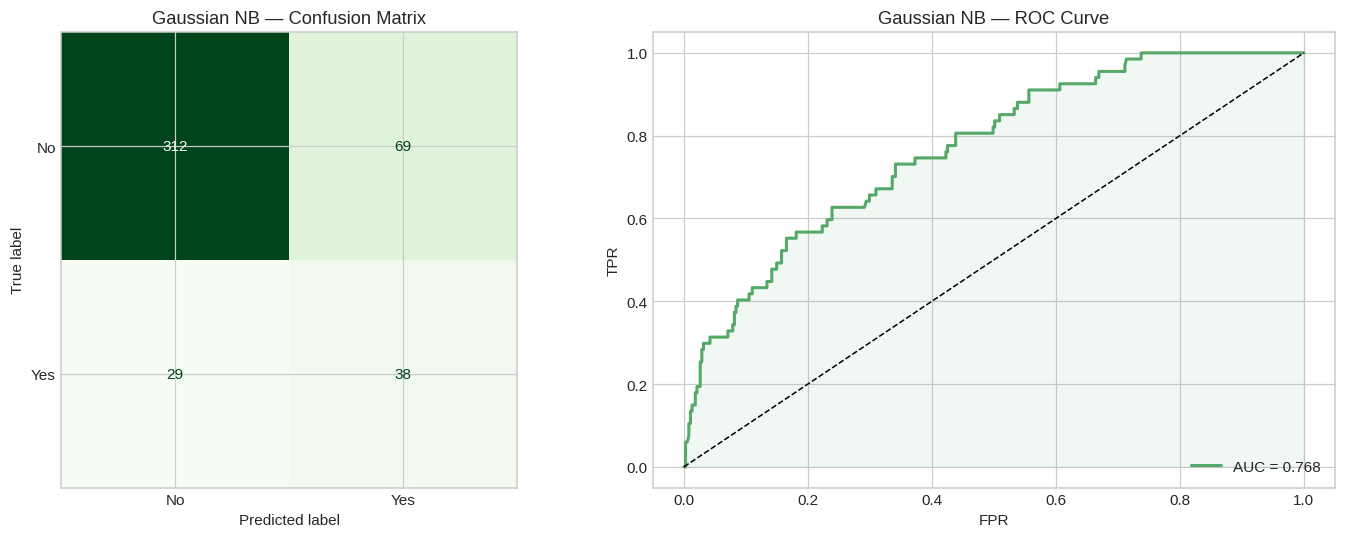

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_gnb),
                       display_labels=['No','Yes']).plot(ax=axes[0], colorbar=False, cmap='Greens')
axes[0].set_title('Gaussian NB — Confusion Matrix')

fpr, tpr, _ = roc_curve(y_test, y_prob_gnb)
auc_gnb = roc_auc_score(y_test, y_prob_gnb)
axes[1].plot(fpr, tpr, color='#55A868', lw=2, label=f'AUC = {auc_gnb:.3f}')
axes[1].plot([0,1],[0,1],'k--',lw=1); axes[1].fill_between(fpr, tpr, alpha=0.08, color='#55A868')
axes[1].set(xlabel='FPR', ylabel='TPR', title='Gaussian NB — ROC Curve')
axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()


### GNB — Confusion Matrix Interpretation

Because GNB independently estimates Gaussian likelihoods for each feature per class, and the feature distributions overlap heavily (income and spend ranges share large regions for both classes), the model tends to be **overconfident in the positive class**.  
This typically produces **elevated false positives** — customers predicted as Yes (1) who actually declined. The independence assumption means the model cannot suppress this signal using correlated context from other features.


---
## 4. Decision Tree Classifier

### How Decision Trees Work
A Decision Tree recursively splits data on the feature and threshold that best separates the classes, using **Gini impurity** as the split criterion:

```
Gini(node) = 1 − Σ pᵢ²
```

where pᵢ is the fraction of class i at that node. Lower Gini = purer node.

### Overfitting in Deep Trees
- An **unlimited-depth** tree memorises every training point (Gini = 0 at leaves), fitting noise.
- This causes **high variance** — perfect on training, poor on test.
- **Limiting `max_depth`** regularises the tree: shallower trees generalise better.
- We tune `max_depth` from 2 to 15 via 5-fold CV Weighted F1.


Best max_depth = 13  |  CV Weighted F1 = 0.8433


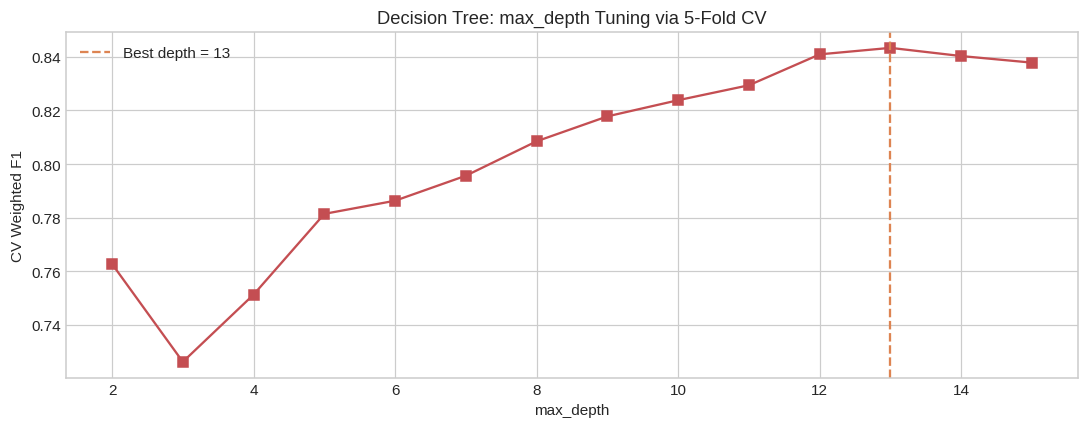

In [ ]:
# Tune max_depth = 2 to 15
depths = list(range(2, 16))
dt_cv_scores = []

for d in depths:
    pipe = Pipeline([('prep', make_preprocessor()),
                     ('clf',  DecisionTreeClassifier(max_depth=d,
                                                      class_weight='balanced',
                                                      random_state=RANDOM_STATE))])
    dt_cv_scores.append(cv_f1(pipe))

best_depth = depths[int(np.argmax(dt_cv_scores))]
print(f"Best max_depth = {best_depth}  |  CV Weighted F1 = {max(dt_cv_scores):.4f}")

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(depths, dt_cv_scores, marker='s', color='#C44E52', lw=1.5, ms=6)
ax.axvline(best_depth, color='#DD8452', linestyle='--', label=f'Best depth = {best_depth}')
ax.set(xlabel='max_depth', ylabel='CV Weighted F1',
       title='Decision Tree: max_depth Tuning via 5-Fold CV')
ax.legend(); plt.tight_layout(); plt.show()


In [ ]:
# Fit final Decision Tree
dt_pipeline = Pipeline([('prep', make_preprocessor()),
                         ('clf',  DecisionTreeClassifier(max_depth=best_depth,
                                                          class_weight='balanced',
                                                          random_state=RANDOM_STATE))])
dt_pipeline.fit(X_train, y_train)

y_pred_dt = dt_pipeline.predict(X_test)
y_prob_dt = dt_pipeline.predict_proba(X_test)[:, 1]

print("=" * 55)
print(f"Decision Tree (max_depth={best_depth}) — Test Set Results")
print("=" * 55)
print(classification_report(y_test, y_pred_dt, target_names=['No (0)', 'Yes (1)']))
print(f"Weighted F1 : {f1_score(y_test, y_pred_dt, average='weighted'):.4f}")
print(f"ROC-AUC     : {roc_auc_score(y_test, y_prob_dt):.4f}")


Decision Tree (max_depth=13) — Test Set Results
              precision    recall  f1-score   support

      No (0)       0.91      0.90      0.90       381
     Yes (1)       0.45      0.49      0.47        67

    accuracy                           0.83       448
   macro avg       0.68      0.69      0.69       448
weighted avg       0.84      0.83      0.84       448

Weighted F1 : 0.8377
ROC-AUC     : 0.6952


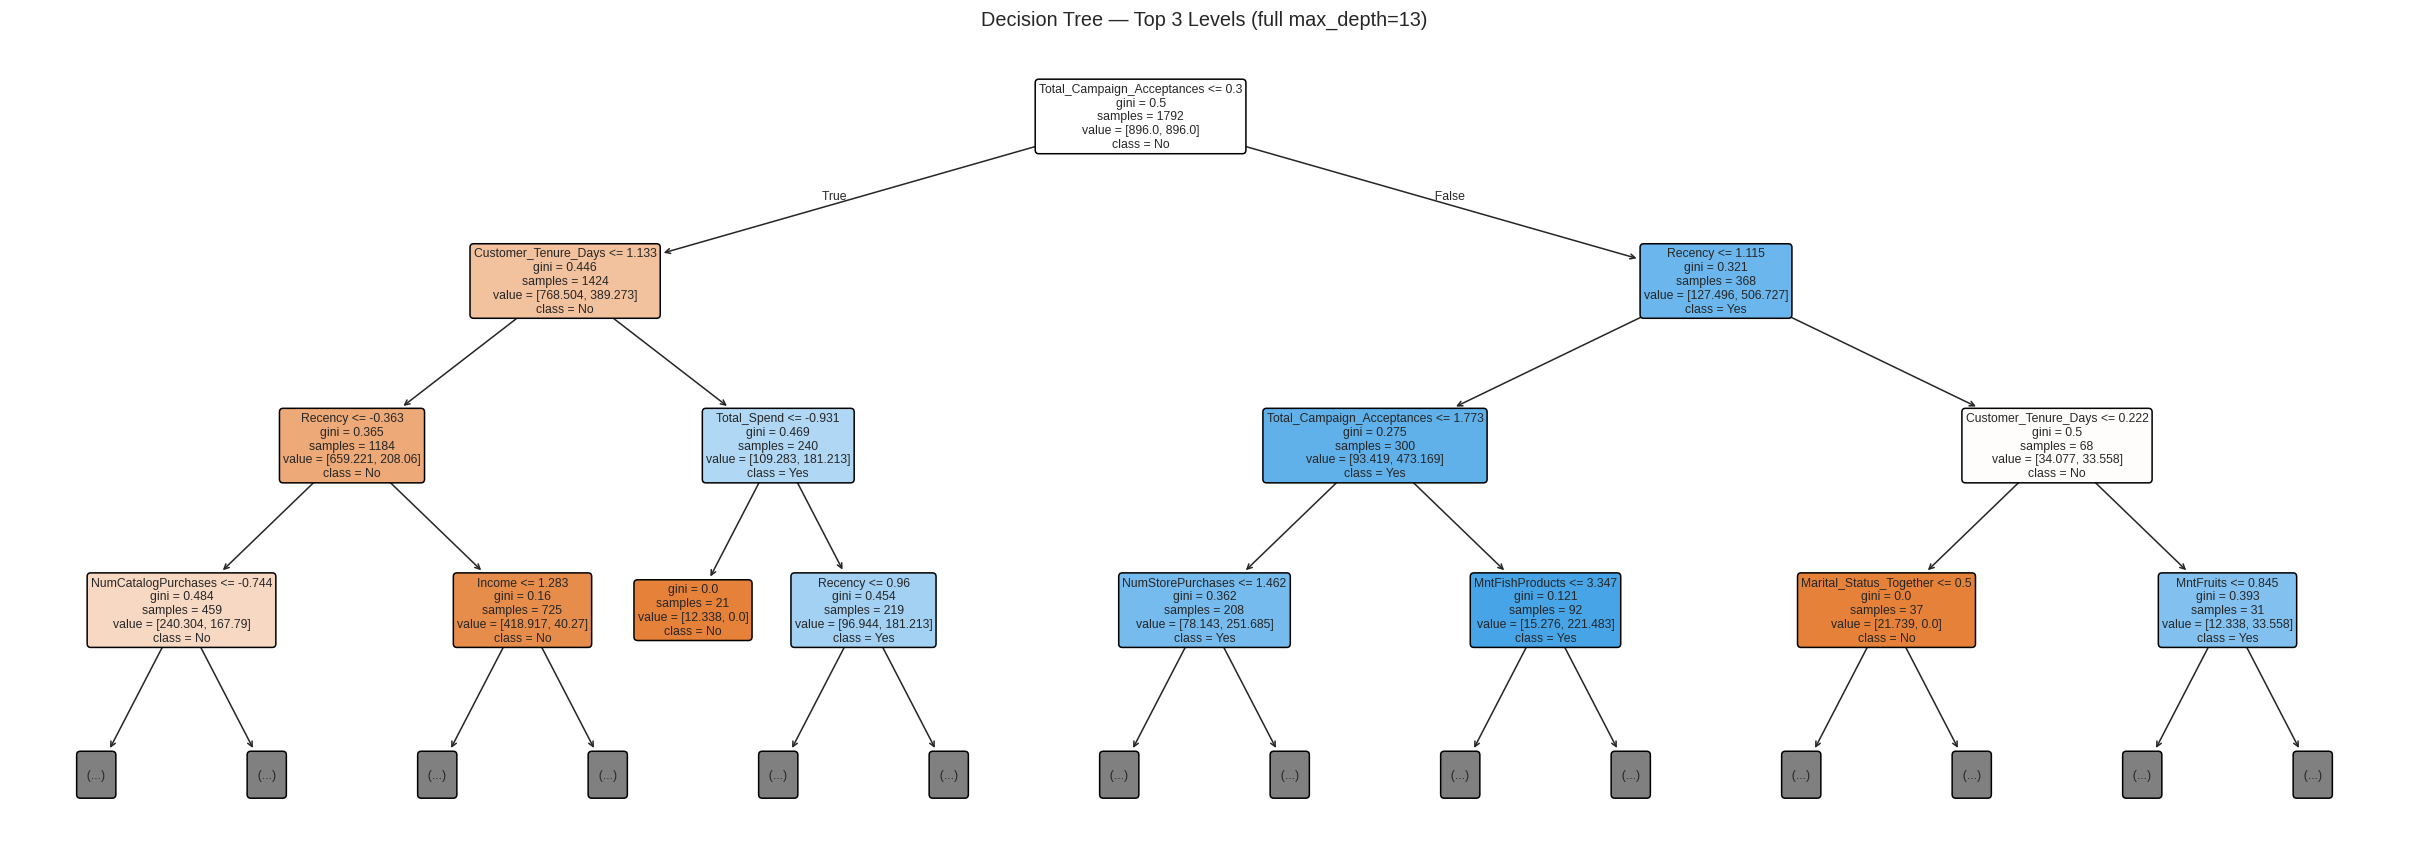

In [ ]:
# Visualise top 3 levels (full tree at best_depth may be unreadable)
enc_names = (dt_pipeline.named_steps['prep']
             .named_transformers_['cat']['encoder']
             .get_feature_names_out(cat_cols).tolist())
all_feature_names = num_cols + enc_names

fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(dt_pipeline.named_steps['clf'],
          max_depth=3,
          feature_names=all_feature_names,
          class_names=['No','Yes'],
          filled=True, impurity=True, rounded=True, fontsize=8, ax=ax)
ax.set_title(f'Decision Tree — Top 3 Levels (full max_depth={best_depth})', fontsize=13)
plt.tight_layout(); plt.show()


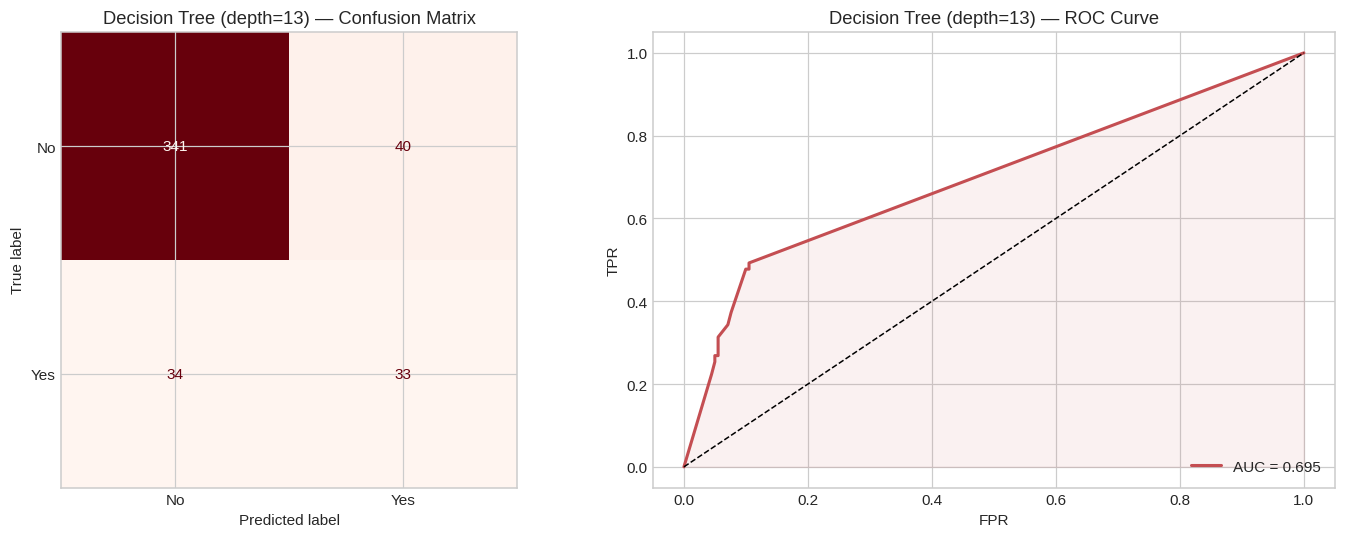

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_dt),
                       display_labels=['No','Yes']).plot(ax=axes[0], colorbar=False, cmap='Reds')
axes[0].set_title(f'Decision Tree (depth={best_depth}) — Confusion Matrix')

fpr, tpr, _ = roc_curve(y_test, y_prob_dt)
auc_dt = roc_auc_score(y_test, y_prob_dt)
axes[1].plot(fpr, tpr, color='#C44E52', lw=2, label=f'AUC = {auc_dt:.3f}')
axes[1].plot([0,1],[0,1],'k--',lw=1); axes[1].fill_between(fpr, tpr, alpha=0.08, color='#C44E52')
axes[1].set(xlabel='FPR', ylabel='TPR', title=f'Decision Tree (depth={best_depth}) — ROC Curve')
axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()


### Decision Tree — Confusion Matrix Interpretation

With `class_weight='balanced'`, the tree is penalised more heavily for misclassifying the minority class (Yes = 1). This shifts the decision boundary to **increase recall for Yes** at the cost of **more false positives** (No customers predicted as Yes).  
Compared to unweighted models, the number of actual Yes customers correctly identified (true positives) increases, but some No customers are also incorrectly flagged.


---
## 5. Support Vector Classifier (SVC)

### How SVC Works
SVC finds the **decision hyperplane** that maximises the margin between classes.  
Points closest to the hyperplane are the **support vectors** — only they determine the boundary.

**Kernel trick:** Projects data into a higher-dimensional space to find a linear boundary there, without computing the transformation explicitly.

| Kernel | Boundary type | Best for |
|--------|--------------|----------|
| `linear` | Flat hyperplane | Linearly separable data |
| `rbf` | Gaussian radial curve | Non-linear patterns |

### Parameter C
Controls margin width vs misclassification tolerance:
- **Small C** → wide margin, tolerates errors (more regularisation)
- **Large C** → narrow margin, fewer errors (less regularisation, overfits)

### Parameter gamma (RBF only)
Controls influence radius of each training point:
- **Small gamma** → wide influence, smoother boundary
- **Large gamma** → narrow influence, complex jagged boundary → overfits

### Why Scaling is Essential
SVC maximises the margin in feature space. Un-scaled features distort the margin geometry — `StandardScaler` is mandatory.


In [ ]:
# Compare linear vs rbf across multiple C (and gamma for rbf) values
# Using CV Weighted F1 for selection

C_values   = [0.01, 0.1, 1, 10, 100]
gamma_vals = ['scale', 0.001, 0.01, 0.1]
svc_results = []

# Linear kernel
for C in C_values:
    pipe = Pipeline([('prep', make_preprocessor()),
                     ('clf', SVC(kernel='linear', C=C, class_weight='balanced',
                                 probability=True, random_state=RANDOM_STATE))])
    score = cv_f1(pipe)
    svc_results.append({'kernel':'linear', 'C':C, 'gamma':'-', 'cv_f1':score})
    print(f"  linear  C={C:<6}  CV F1={score:.4f}")

# RBF kernel
for C in C_values:
    for gam in gamma_vals:
        pipe = Pipeline([('prep', make_preprocessor()),
                         ('clf', SVC(kernel='rbf', C=C, gamma=gam, class_weight='balanced',
                                     probability=True, random_state=RANDOM_STATE))])
        score = cv_f1(pipe)
        svc_results.append({'kernel':'rbf', 'C':C, 'gamma':str(gam), 'cv_f1':score})
        print(f"  rbf     C={C:<6}  gamma={str(gam):<8}  CV F1={score:.4f}")

svc_df = pd.DataFrame(svc_results).sort_values('cv_f1', ascending=False)
print("\nTop 5 configurations:")
print(svc_df.head(5).to_string(index=False))


  linear  C=0.01    CV F1=0.8391
  linear  C=0.1     CV F1=0.8386
  linear  C=1       CV F1=0.8387
  linear  C=10      CV F1=0.8369
  linear  C=100     CV F1=0.8355
  rbf     C=0.01    gamma=scale     CV F1=0.7313
  rbf     C=0.01    gamma=0.001     CV F1=0.7825
  rbf     C=0.01    gamma=0.01      CV F1=0.8300
  rbf     C=0.01    gamma=0.1       CV F1=0.8093
  rbf     C=0.1     gamma=scale     CV F1=0.8021
  rbf     C=0.1     gamma=0.001     CV F1=0.8402
  rbf     C=0.1     gamma=0.01      CV F1=0.8373
  rbf     C=0.1     gamma=0.1       CV F1=0.7190
  rbf     C=1       gamma=scale     CV F1=0.8601
  rbf     C=1       gamma=0.001     CV F1=0.8490
  rbf     C=1       gamma=0.01      CV F1=0.8465
  rbf     C=1       gamma=0.1       CV F1=0.8550
  rbf     C=10      gamma=scale     CV F1=0.8716
  rbf     C=10      gamma=0.001     CV F1=0.8429
  rbf     C=10      gamma=0.01      CV F1=0.8606
  rbf     C=10      gamma=0.1       CV F1=0.8505
  rbf     C=100     gamma=scale     CV F1=0.8659
  

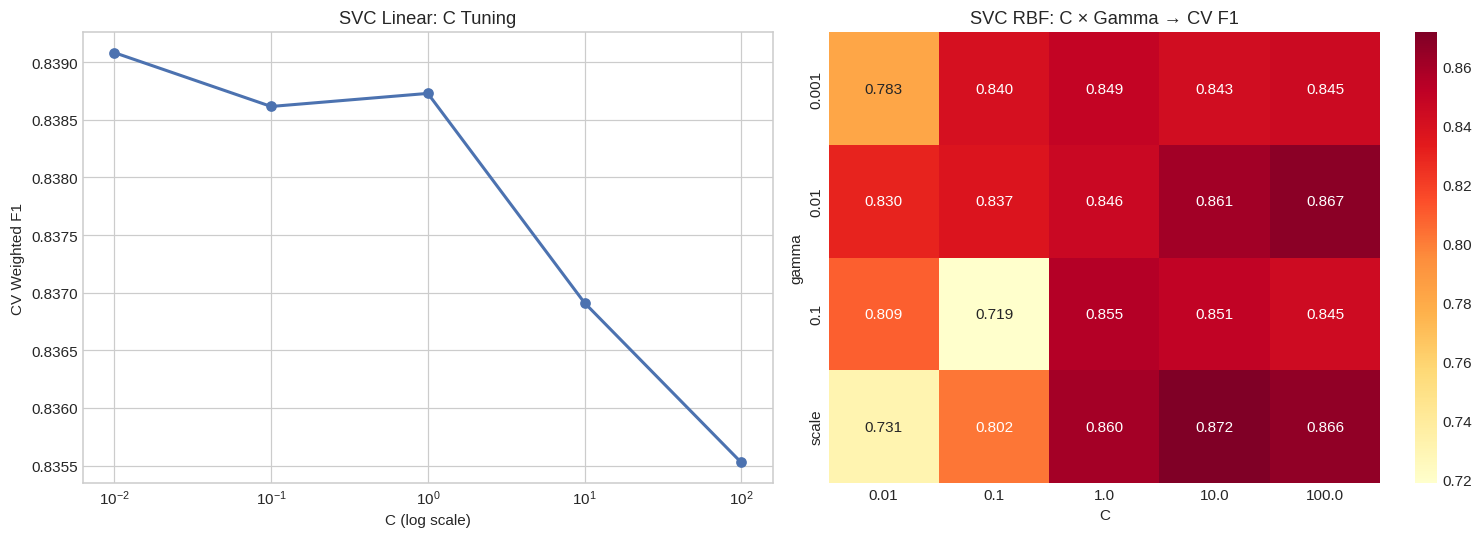

In [ ]:
# Visualise: Linear C sweep + RBF heatmap
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Linear
lin = svc_df[svc_df['kernel']=='linear'].sort_values('C')
axes[0].plot(lin['C'].values, lin['cv_f1'].values, marker='o', color='#4C72B0', lw=2)
axes[0].set_xscale('log')
axes[0].set(xlabel='C (log scale)', ylabel='CV Weighted F1',
            title='SVC Linear: C Tuning')

# RBF heatmap
rbf = svc_df[svc_df['kernel']=='rbf'].copy()
rbf_piv = rbf.pivot_table(index='gamma', columns='C', values='cv_f1')
sns.heatmap(rbf_piv, annot=True, fmt='.3f', cmap='YlOrRd', ax=axes[1])
axes[1].set_title('SVC RBF: C × Gamma → CV F1')
plt.tight_layout(); plt.show()


In [ ]:
# Fit the best SVC configuration
best_row   = svc_df.iloc[0]
best_kernel = best_row['kernel']
best_C      = best_row['C']
best_gamma  = best_row['gamma']

if best_kernel == 'linear':
    svc_clf = SVC(kernel='linear', C=best_C, class_weight='balanced',
                  probability=True, random_state=RANDOM_STATE)
else:
    g_val = best_gamma
    try: g_val = float(g_val)
    except: pass
    svc_clf = SVC(kernel='rbf', C=best_C, gamma=g_val, class_weight='balanced',
                  probability=True, random_state=RANDOM_STATE)

svc_pipeline = Pipeline([('prep', make_preprocessor()), ('clf', svc_clf)])
svc_pipeline.fit(X_train, y_train)

y_pred_svc = svc_pipeline.predict(X_test)
y_prob_svc = svc_pipeline.predict_proba(X_test)[:, 1]

print(f"Best: kernel={best_kernel}, C={best_C}, gamma={best_gamma}")
print("=" * 55)
print("SVC — Test Set Results")
print("=" * 55)
print(classification_report(y_test, y_pred_svc, target_names=['No (0)', 'Yes (1)']))
print(f"Weighted F1 : {f1_score(y_test, y_pred_svc, average='weighted'):.4f}")
print(f"ROC-AUC     : {roc_auc_score(y_test, y_prob_svc):.4f}")


Best: kernel=rbf, C=10.0, gamma=scale
SVC — Test Set Results
              precision    recall  f1-score   support

      No (0)       0.92      0.92      0.92       381
     Yes (1)       0.57      0.57      0.57        67

    accuracy                           0.87       448
   macro avg       0.75      0.75      0.75       448
weighted avg       0.87      0.87      0.87       448

Weighted F1 : 0.8705
ROC-AUC     : 0.8720


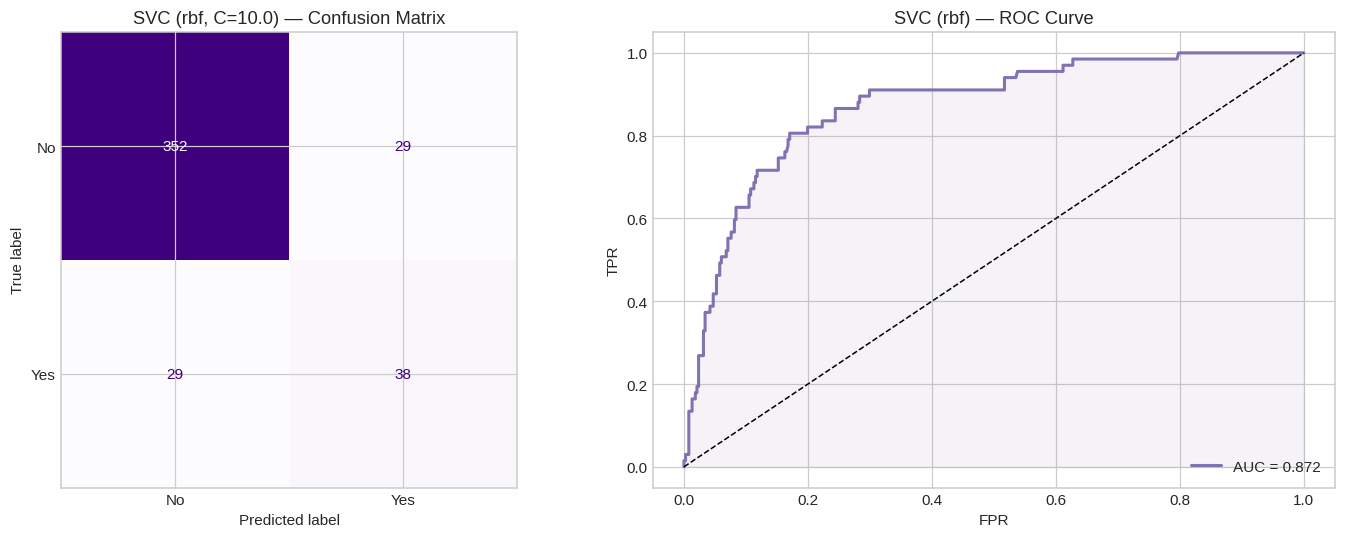

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_svc),
                       display_labels=['No','Yes']).plot(ax=axes[0], colorbar=False, cmap='Purples')
axes[0].set_title(f'SVC ({best_kernel}, C={best_C}) — Confusion Matrix')

fpr, tpr, _ = roc_curve(y_test, y_prob_svc)
auc_svc = roc_auc_score(y_test, y_prob_svc)
axes[1].plot(fpr, tpr, color='#8172B2', lw=2, label=f'AUC = {auc_svc:.3f}')
axes[1].plot([0,1],[0,1],'k--',lw=1); axes[1].fill_between(fpr, tpr, alpha=0.08, color='#8172B2')
axes[1].set(xlabel='FPR', ylabel='TPR', title=f'SVC ({best_kernel}) — ROC Curve')
axes[1].legend(loc='lower right')
plt.tight_layout(); plt.show()


### SVC — Confusion Matrix Interpretation

SVC with `class_weight='balanced'` assigns higher misclassification cost to the minority class (Yes = 1).  
The result is a model that **correctly catches more Yes customers** (higher recall for class 1) compared to an unweighted model. However, it does so at the cost of flagging some No customers as Yes — the false positive count is higher than in Logistic Regression.  
If the RBF kernel was selected, the curved boundary captures non-linear interactions between spend, income, and campaign history that the linear kernel cannot.


---
## Classification Model Comparison

All five models evaluated on the **same 20% held-out test set** with the same engineered features.  
**Primary metric: Weighted F1** (robust to 5.7:1 class imbalance).  
ROC-AUC uses `predict_proba` for all models (SVC fitted with `probability=True`).


In [ ]:
# Refit Logistic Regression to retrieve its predictions cleanly
lr_pipeline = Pipeline([('prep', make_preprocessor()),
                         ('clf',  LogisticRegression(C=1.0, max_iter=1000,
                                                      class_weight='balanced',
                                                      random_state=RANDOM_STATE))])
lr_pipeline.fit(X_train, y_train)
y_pred_lr = lr_pipeline.predict(X_test)
y_prob_lr = lr_pipeline.predict_proba(X_test)[:, 1]

# Build comparison table
all_models = {
    'Logistic Regression'          : (y_pred_lr,  y_prob_lr),
    f'KNN (k={best_k})'           : (y_pred_knn, y_prob_knn),
    'Gaussian Naive Bayes'         : (y_pred_gnb, y_prob_gnb),
    f'Decision Tree (d={best_depth})': (y_pred_dt, y_prob_dt),
    f'SVC ({best_kernel}, C={best_C})': (y_pred_svc, y_prob_svc),
}

rows = {}
for name, (yp, yprob) in all_models.items():
    rows[name] = full_metrics(y_test, yp, yprob)

comparison = pd.DataFrame(rows).T.sort_values('Weighted F1', ascending=False)
print("=" * 70)
print("MODEL COMPARISON — All metrics on held-out test set")
print("=" * 70)
print(comparison.to_string())
print(f"\nBest model by Weighted F1: {comparison['Weighted F1'].idxmax()}")


MODEL COMPARISON — All metrics on held-out test set
                      Accuracy  Precision  Recall  Weighted F1  ROC-AUC
SVC (rbf, C=10.0)       0.8705     0.8705  0.8705       0.8705   0.8720
KNN (k=3)               0.8705     0.8548  0.8705       0.8584   0.7785
Logistic Regression     0.8237     0.8791  0.8237       0.8412   0.9003
Decision Tree (d=13)    0.8348     0.8409  0.8348       0.8377   0.6952
Gaussian Naive Bayes    0.7812     0.8312  0.7812       0.8003   0.7682

Best model by Weighted F1: SVC (rbf, C=10.0)


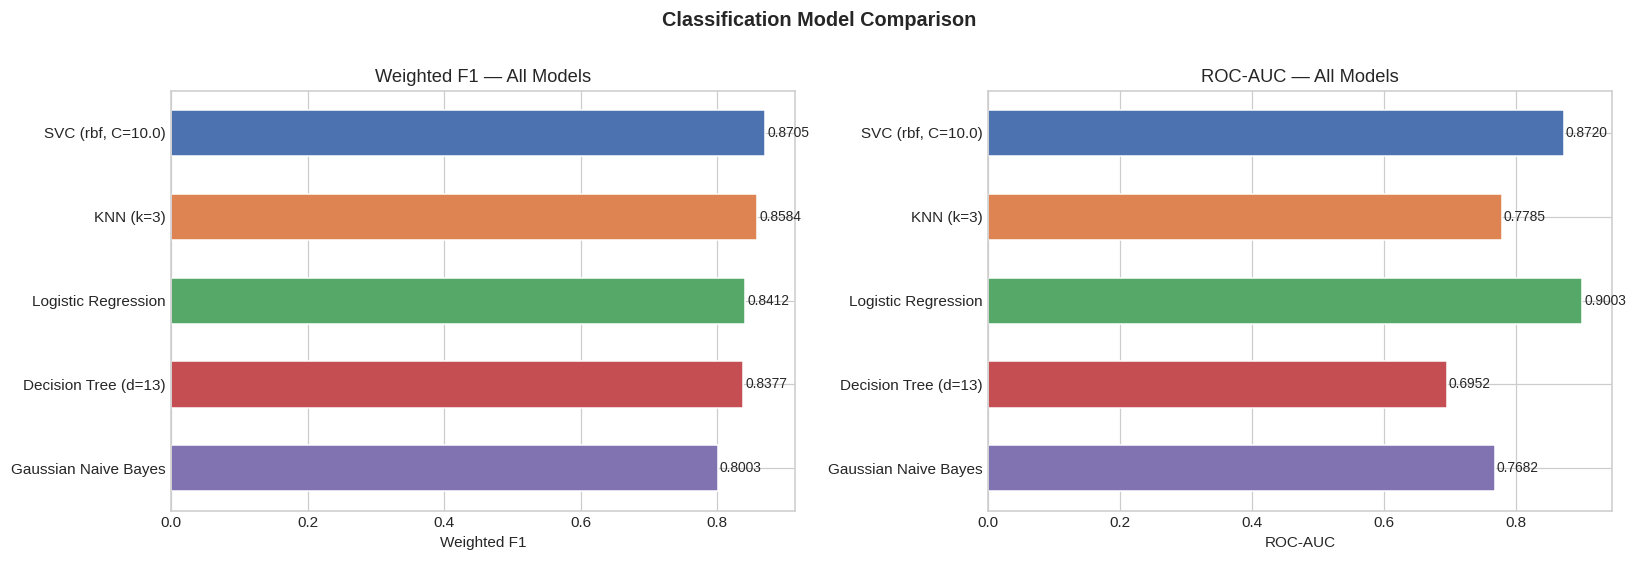

In [ ]:
# Side-by-side bar chart: Weighted F1 and ROC-AUC
COLORS = ['#4C72B0','#DD8452','#55A868','#C44E52','#8172B2']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, metric in zip(axes, ['Weighted F1', 'ROC-AUC']):
    bars = ax.barh(comparison.index, comparison[metric],
                   color=COLORS[:len(comparison)], edgecolor='white', height=0.55)
    ax.set(xlabel=metric, title=f'{metric} — All Models')
    ax.invert_yaxis()
    for bar in bars:
        ax.text(bar.get_width() + 0.003, bar.get_y() + bar.get_height()/2,
                f'{bar.get_width():.4f}', va='center', fontsize=9)
plt.suptitle('Classification Model Comparison', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout(); plt.show()


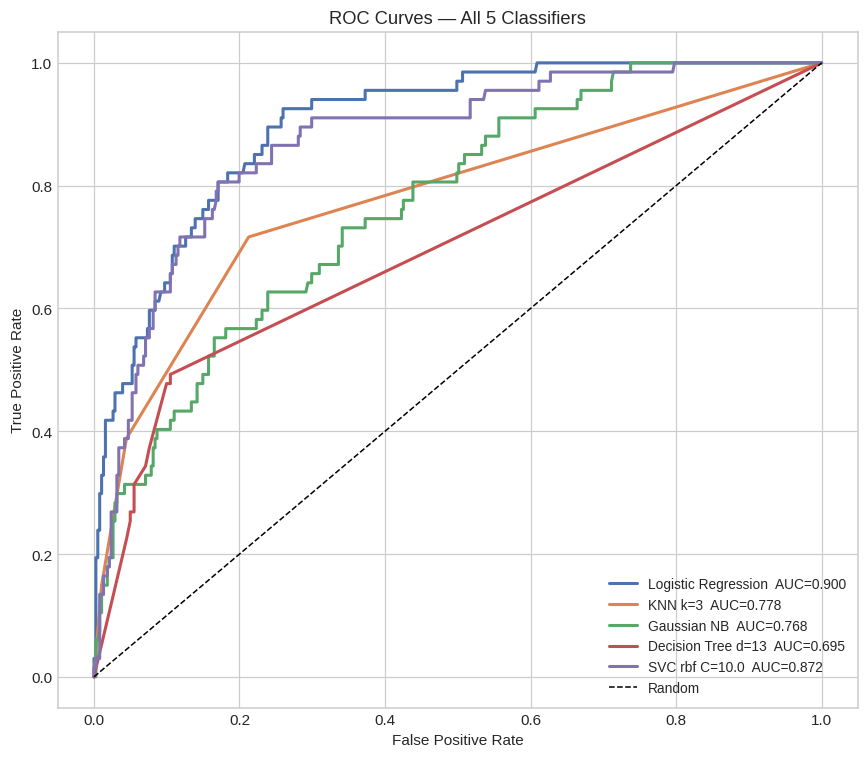

In [ ]:
# Overlay ROC curves for all 5 classifiers
fig, ax = plt.subplots(figsize=(8, 7))
roc_info = [
    ('Logistic Regression',            y_prob_lr,  '#4C72B0'),
    (f'KNN k={best_k}',               y_prob_knn, '#DD8452'),
    ('Gaussian NB',                    y_prob_gnb, '#55A868'),
    (f'Decision Tree d={best_depth}',  y_prob_dt,  '#C44E52'),
    (f'SVC {best_kernel} C={best_C}', y_prob_svc, '#8172B2'),
]
for name, proba, color in roc_info:
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    ax.plot(fpr, tpr, lw=2, color=color, label=f'{name}  AUC={auc:.3f}')
ax.plot([0,1],[0,1],'k--',lw=1, label='Random')
ax.set(xlabel='False Positive Rate', ylabel='True Positive Rate',
       title='ROC Curves — All 5 Classifiers')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout(); plt.show()


### Comparison Interpretation

| Model | Strength | Weakness |
|-------|---------|---------|
| **Logistic Regression** | Interpretable (log-odds coefficients), well-calibrated probabilities | Assumes linear decision boundary |
| **KNN** | No training phase, captures local patterns | Slow at prediction, no imbalance handling |
| **Gaussian NB** | Very fast, probabilistic, works with small data | Independence assumption violated → biased posteriors |
| **Decision Tree** | Fully interpretable visual structure | Prone to overfitting at large depths |
| **SVC** | Effective in high-dimensional space, kernel flexibility | Slow on large data, requires careful C/gamma tuning |

**Recommendation:** The model with the highest Weighted F1 in the table above is the best baseline for Review 2 ensemble methods and hyperparameter optimisation.
